### My GCP Bucket Name is:-

bwt-aiml-gcp-2026-batch

### Create VM Instances:-

- 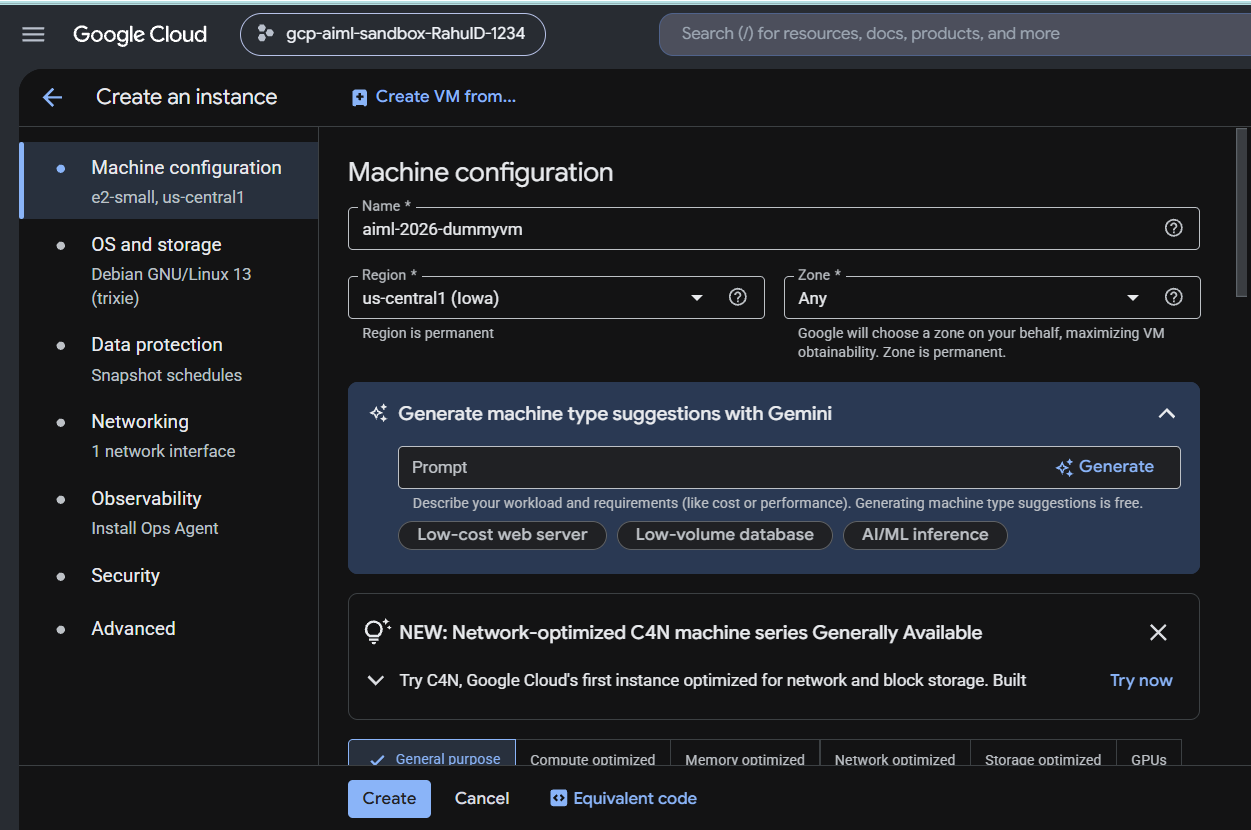
- 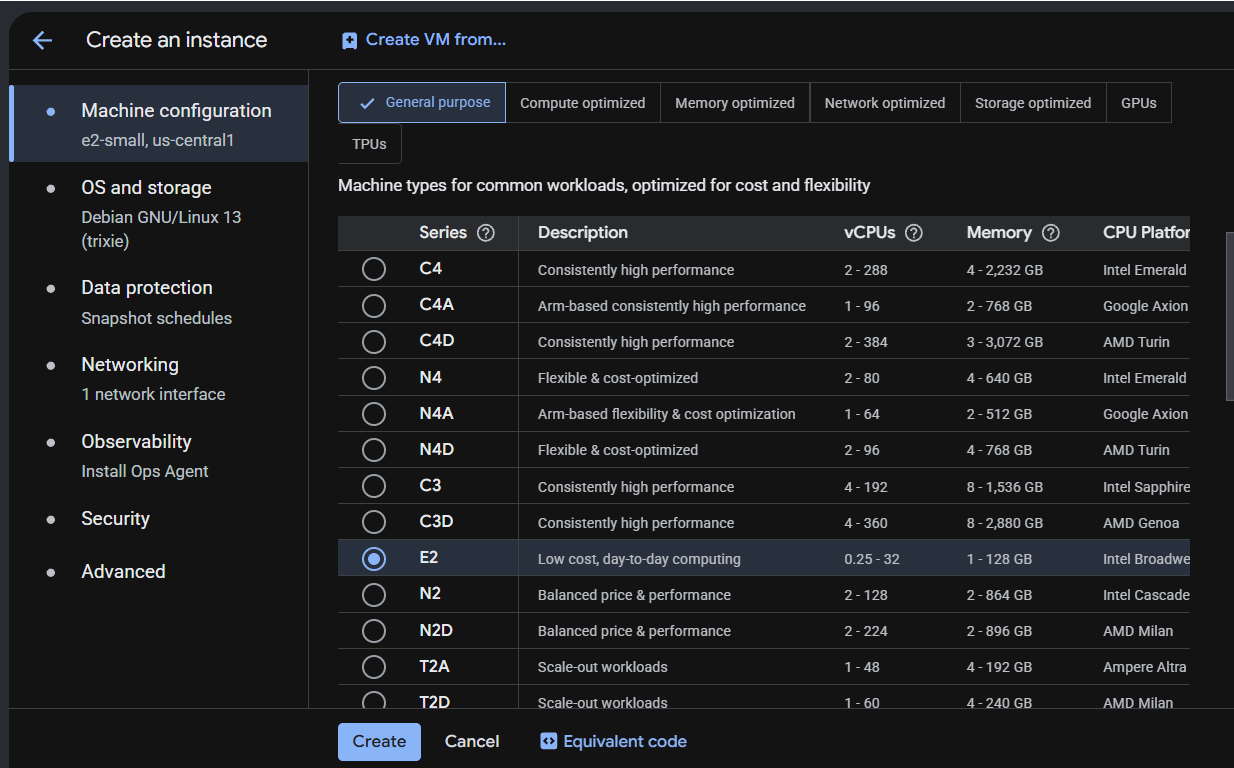


### By using Gcloud:_

```python
gcloud compute ssh --zone "us-central1-a" "aiml-2026-dummyvm" --project "gcp-aiml-sandbox-rahuld-1234"
```
- 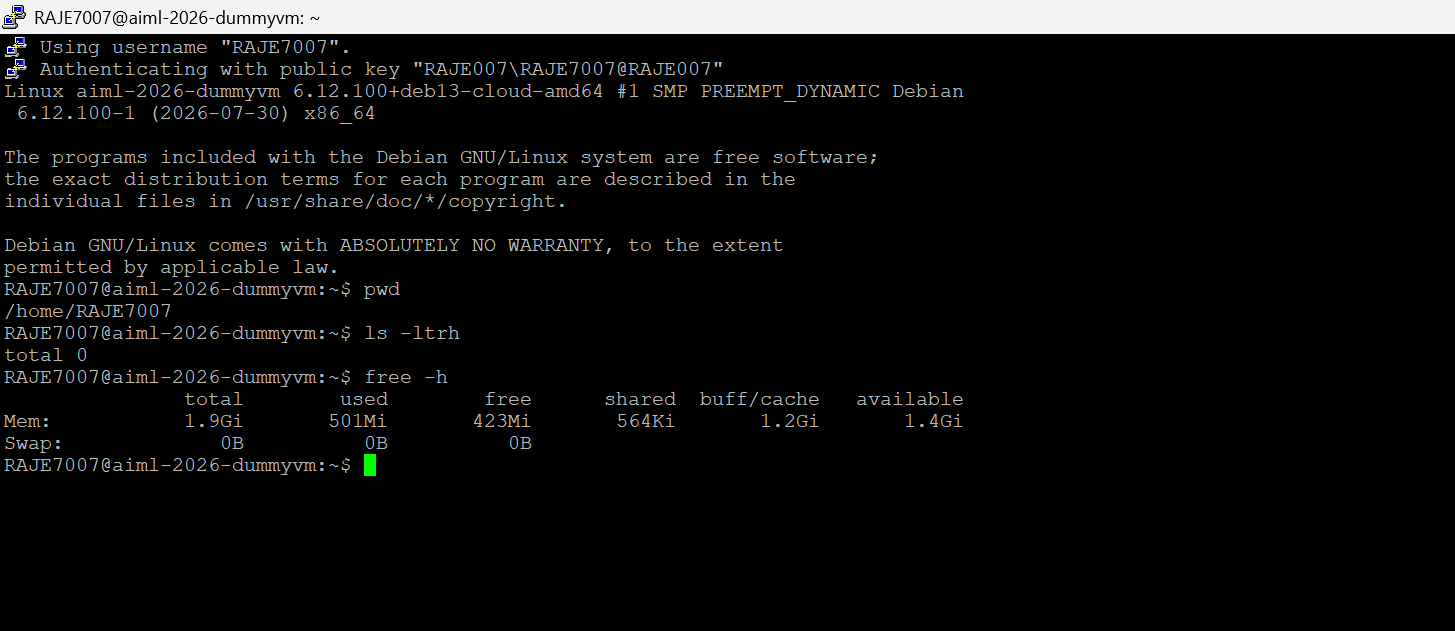


### SSH Key
- 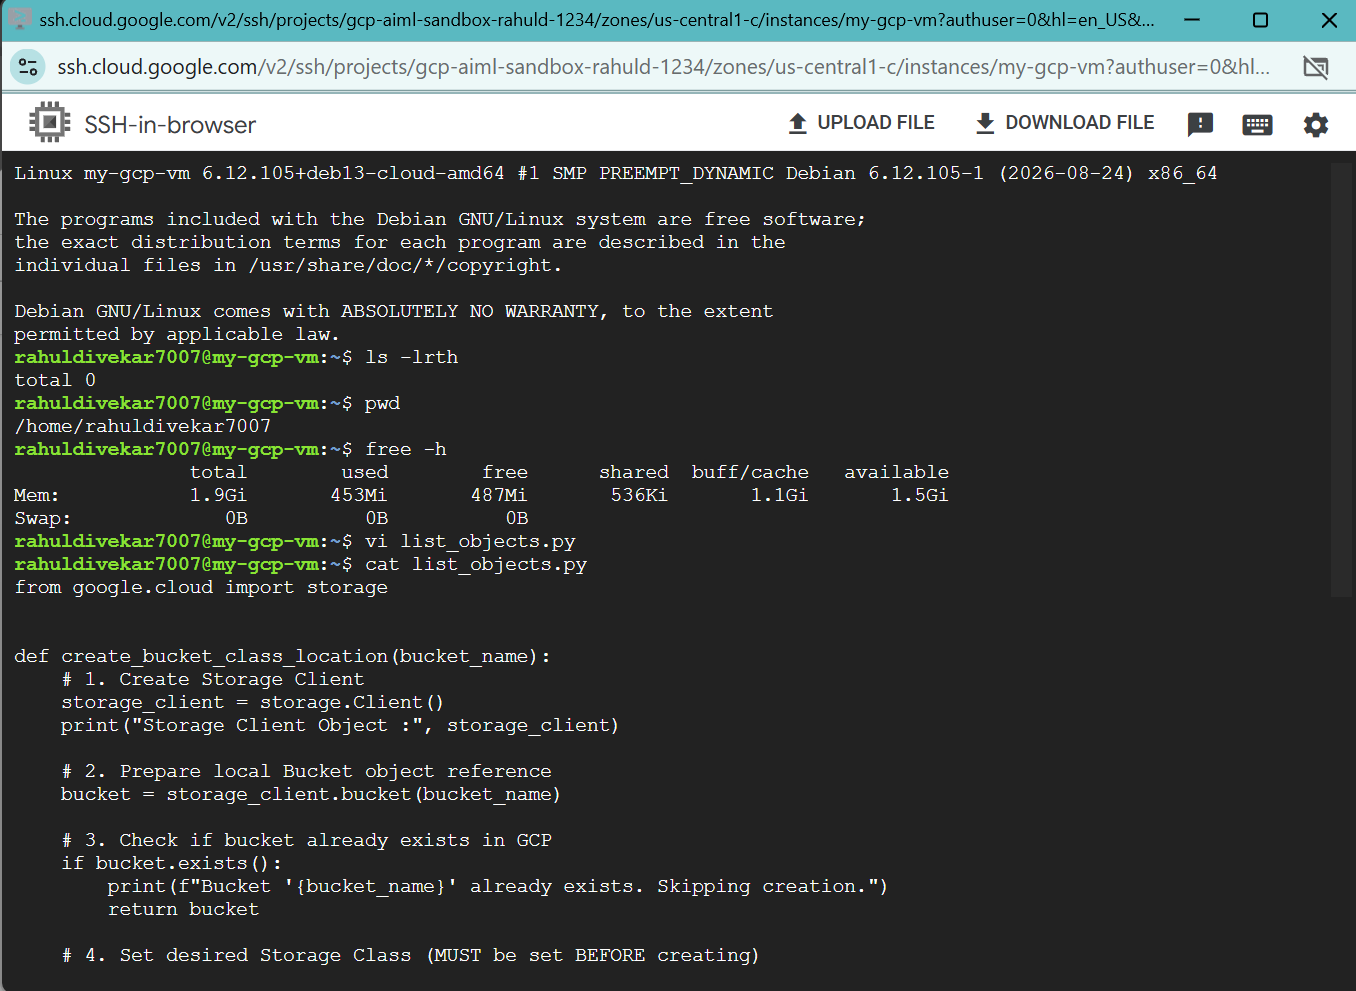
- 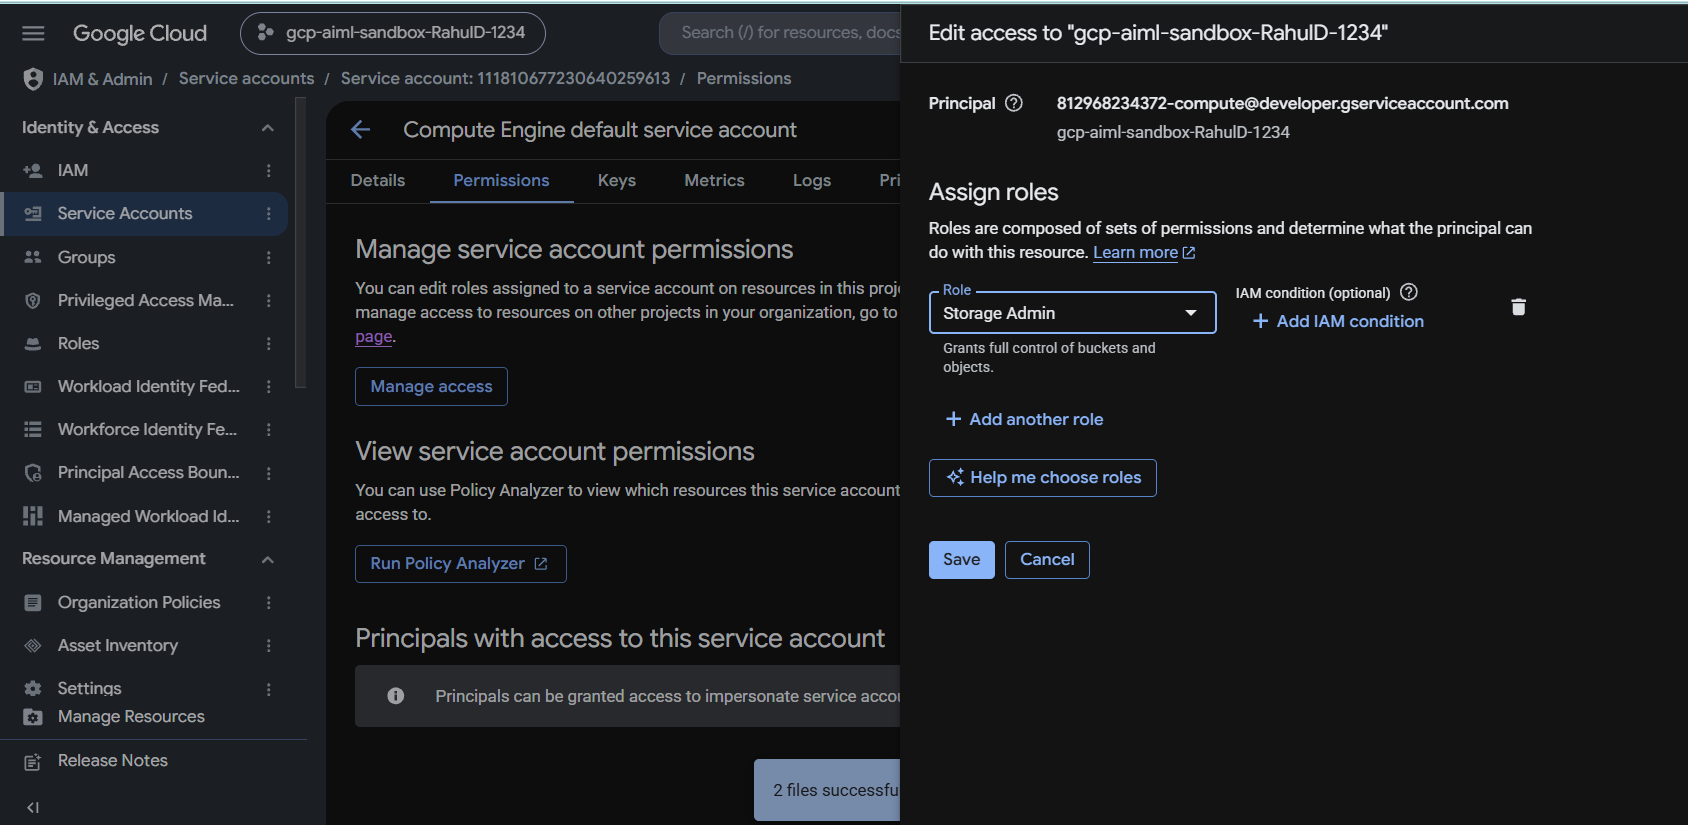


```python
from google.cloud import storage


def create_bucket_class_location(bucket_name):
    # 1. Create Storage Client
    storage_client = storage.Client()
    print("Storage Client Object :", storage_client)

    # 2. Prepare local Bucket object reference
    bucket = storage_client.bucket(bucket_name)

    # 3. Check if bucket already exists in GCP
    if bucket.exists():
        print(f"Bucket '{bucket_name}' already exists. Skipping creation.")
        return bucket

    # 4. Set desired Storage Class (MUST be set BEFORE creating)
    bucket.storage_class = "COLDLINE"

    # 5. Create Bucket in GCP (US region + COLDLINE class)
    new_bucket = storage_client.create_bucket(bucket, location="US")

    print(
        "Created bucket {} in {} with storage class {}".format(
            new_bucket.name,
            new_bucket.location,
            new_bucket.storage_class,
        )
    )

    return new_bucket


# -----------------------------
# Main Program
# -----------------------------
if __name__ == "__main__":

    # Bucket name must be globally unique
    bucket_name = "bwt-aiml-gcp-2026-batch"

    val = create_bucket_class_location(bucket_name)

    print("-" * 40)
    print("Result Bucket Object:", val)
    print("-" * 40)

```
---

### Sudo Commands

```python
sudo apt update
```
- 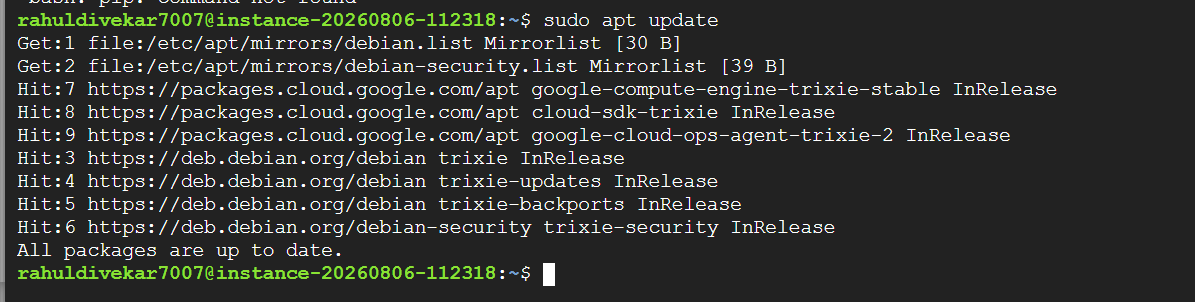

---

```python
sudo apt install python3.13-venv

```
---
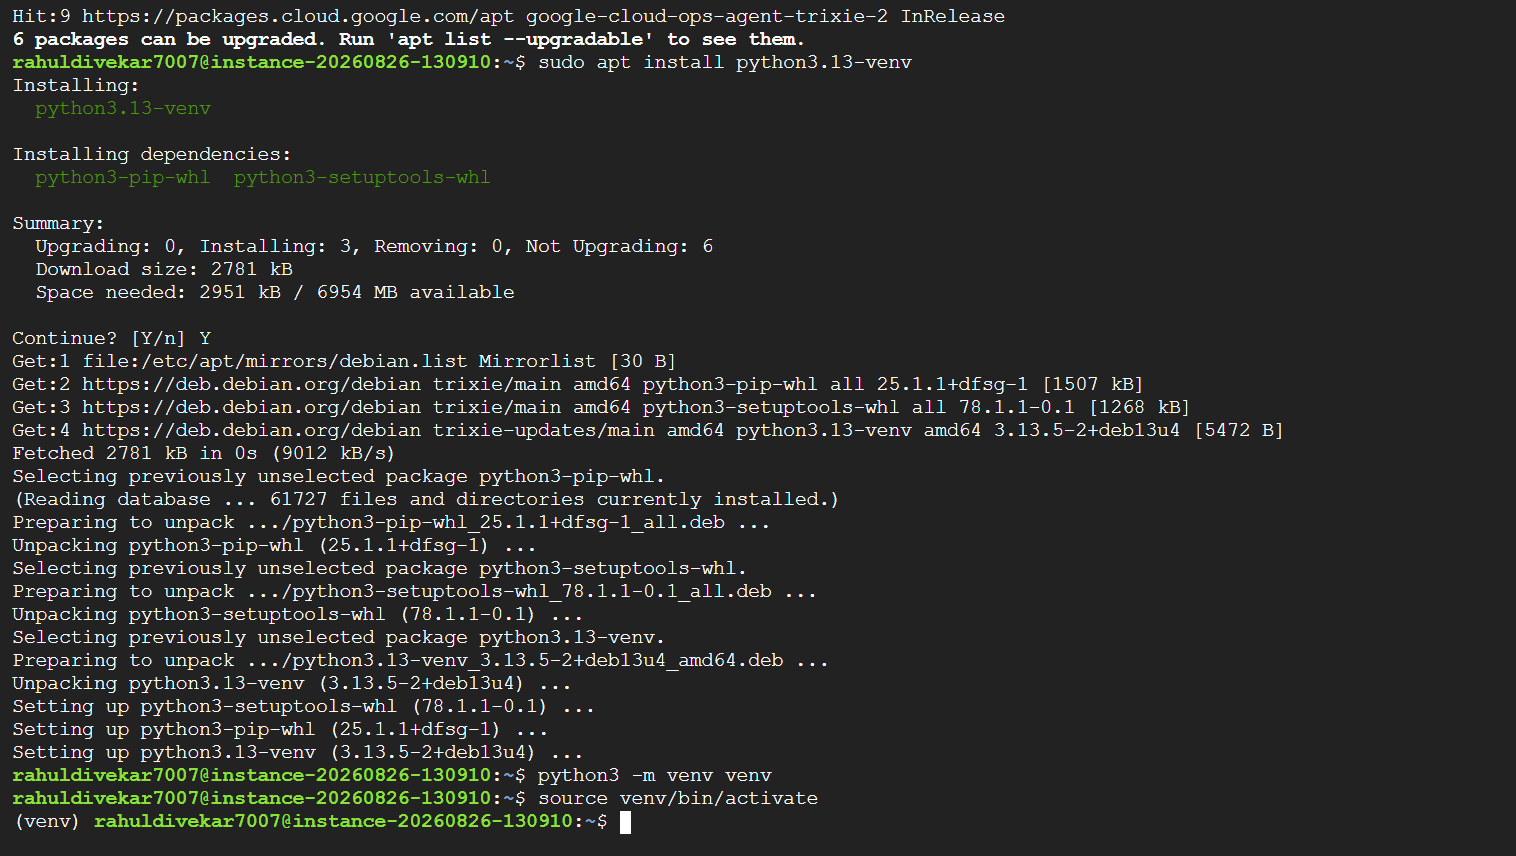
```python
python3 -m venv venv
```
---
```python

source venv/bin/activate
```
---
```python
pip list
```
---

```python
pip install google-cloud-storage
```
---

```python
pip list
```
---

```python
ls -lrth
```
---

```python
python list_objects.py
```
---

- 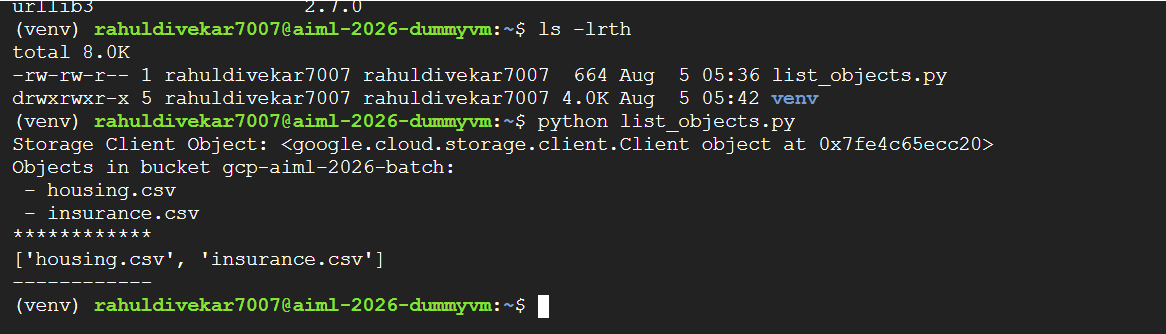

# dev_private_key

- 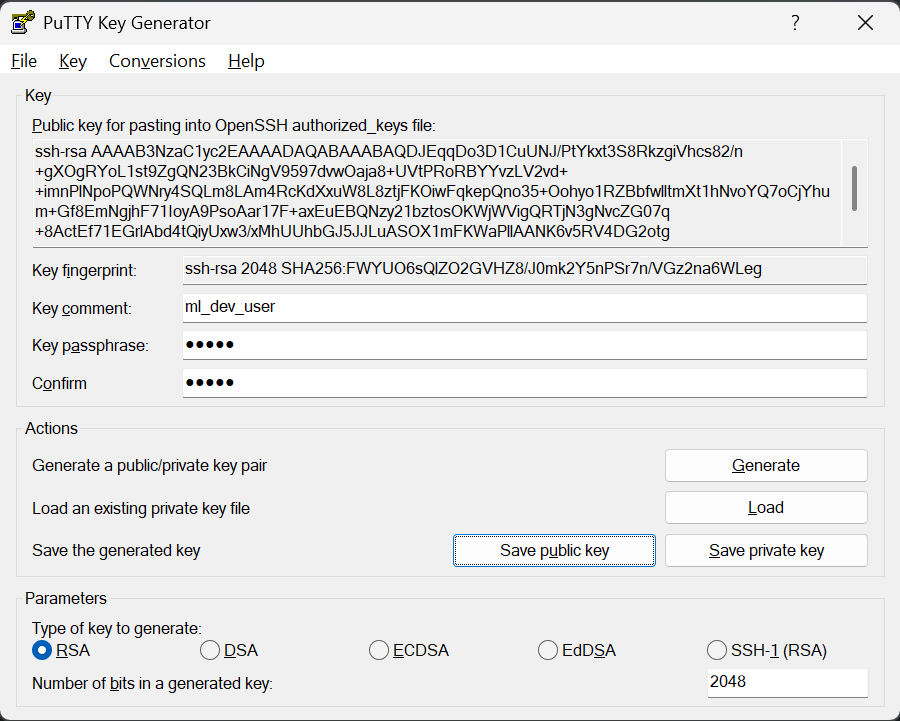

# Metadata

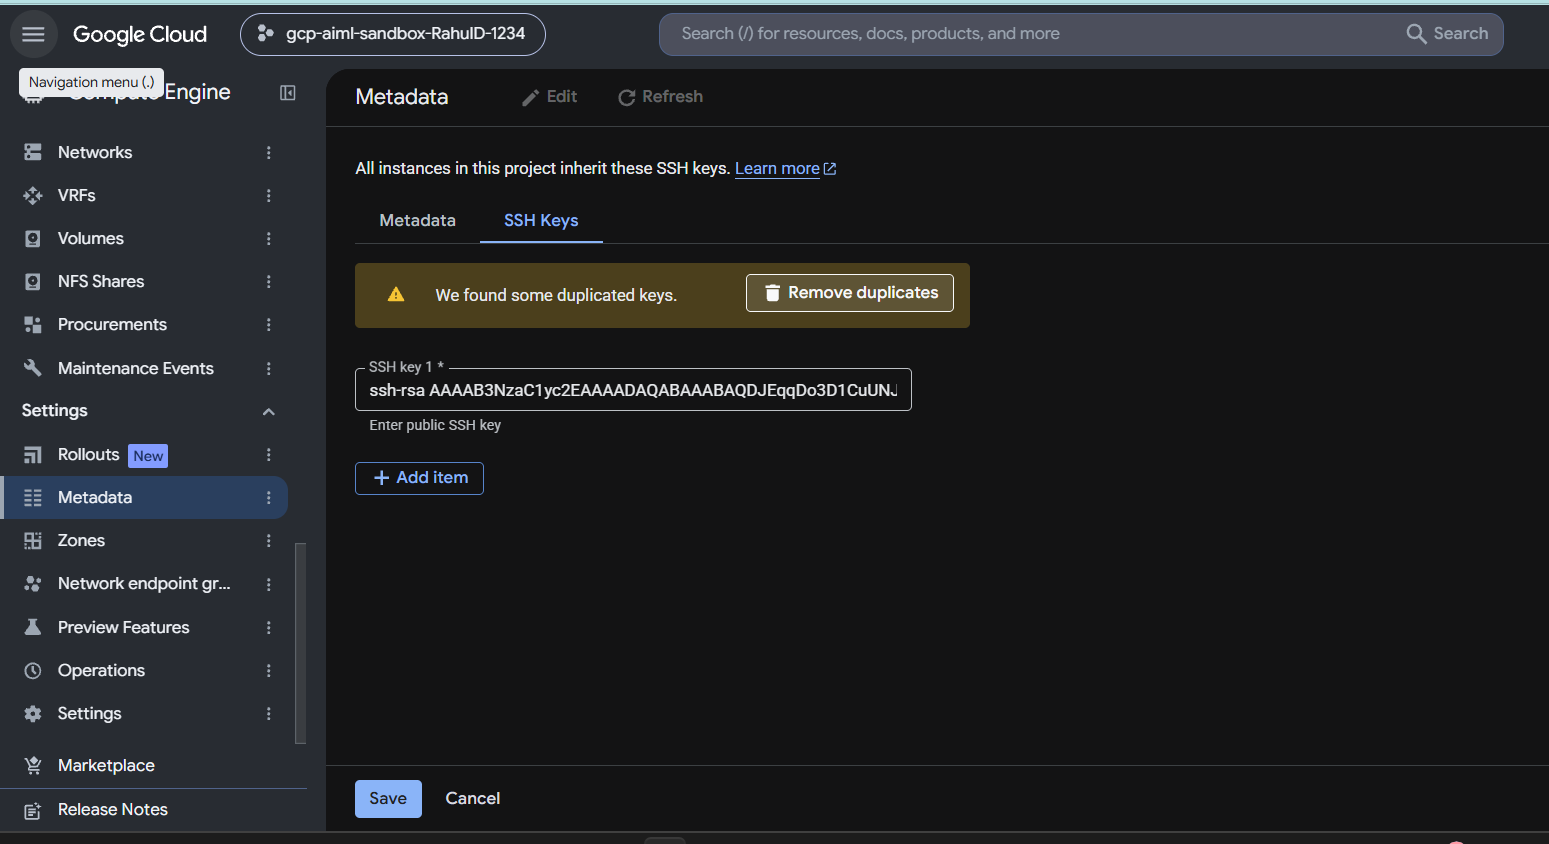


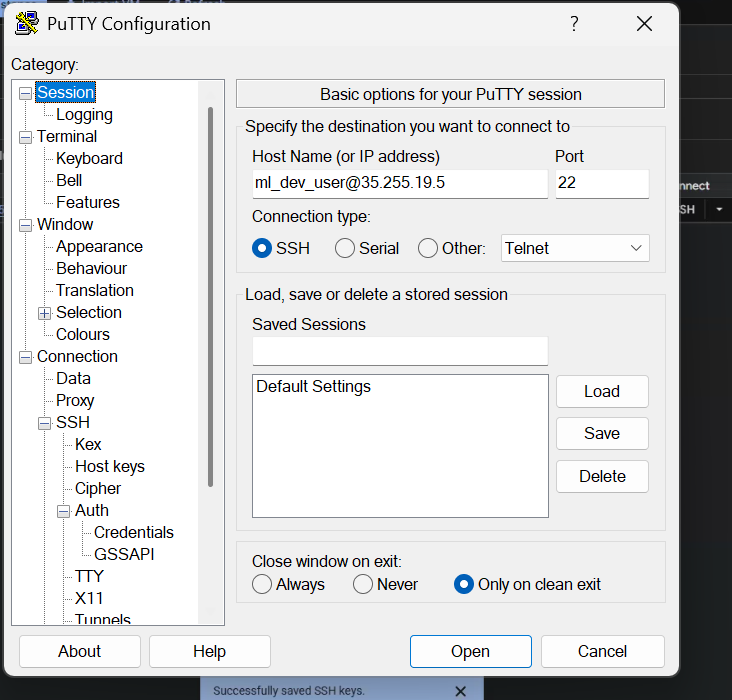

## VSCode
```bash
gcloud auth login

gcloud config list
```
---
```bash
gcloud init
```
---

```bash
gcloud compute config-ssh
```
---

```bash 
gcloud config set project gcp-aiml-sandbox-rahuld-1234
```
---
```bash
Ctrl + Shift + P -> remote-ssh: connect to host -> instance -> Linux -> if error then -> go to CMD -> gcloud compute ssh instance-20260827-055620 --zone=us-central1-a --project=gcp-aiml-sandbox-rahuld-1234 -> then -> In VS Code, press Ctrl + Shift + P -> Type Open SSH Configuration File and select C:\Users\<YourName>\.ssh\config 
```
---

# Complete Solution for this Error:-
```bash
STEP 1: Generate a Clean SSH Key on Windows (Takes 30 seconds)

Open Command Prompt (CMD) on Windows.

Run this exact command: 
`
ssh-keygen -t rsa -f C:\Users\rahul\.ssh\gcp_vscode_key -C rahuldivekar7007
`

When it asks for a passphrase, press Enter twice (leave it empty).
```
---

```bash
STEP 2: Add the Key to Google Cloud Web Console:-

1. Open Command Prompt and view your new public key by running: 
`
type C:\Users\rahul\.ssh\gcp_vscode_key.pub
`
ssh-rsa AAAAB3NzaC1yc2EAAAADAQABAAABgQCyYIFfDaXJBLIeeN6vtHkr9xOyiI8VrmXVsQreB1muhyyeh+TP342vdg9bRgrs1bDYz9YRSNiCxwWE7uKqXkZDM+EhdK0qr77TrDTqjUUYe2CJMtJkFEc9rRT4FFBcsQiYoawigLgNDXHkgHEqjjWOLEHlZuPtfuA7niw6S4rmBJz44f5egSmA90s7R43aYxMbHUoSASEYZJE4SlE146HhNoP2gREjK9qtwTwHLb1QiJeP3cGod/M8/pxOpM9Rr0NU4A6SlulMrc+RXAnE43SbIGe6yk7V9TStVi/fmqUmTVhRE2e6QOKYhfXTNP+VKlNS6tYwoQweU2/NwNlvDYIgCvsvXejbVYC/moiXJy1B6nMbtAI3RGI4DVVKH6R74WCnY0zUJU2YmQGs4EOx6bX1KcP6t4RQt8z9o2gRiy+TOmJgAZvkLT3G4JqIqLp+P9crO5XTuQgMyi/mOc/eANp/YtxqRpXJZ6Eys67BWJvc9HoSnlFY9lHsnlLphY/0Fk0= rahuldivekar7007

2. Copy the entire output text that appears (it starts with ssh-rsa ... and ends with rahuldivekar7007).

3. Now go to Google Cloud Console VM Page in your web browser.

4. Click on the name of your VM (instance-20260827-055620).

5. Click EDIT at the top bar.

6. Scroll down to the SSH Keys section.

7. Click + ADD ITEM.

8. Paste the text you copied into the box. (GCP will automatically detect the username rahuldivekar7007).

9. Scroll to the very bottom and click SAVE.
```

---
```bash
STEP 3: Configure VS Code SSH Settings:-

1. Open VS Code on your computer.

2. Press Ctrl + Shift + P.

3. Type and select: Remote-SSH: Open SSH Configuration File...

4. Select C:\Users\rahul\.ssh\config.

5. Erase everything inside that file and paste this clean configuration:

Host my-gcp-vm
    HostName YOUR_VM_EXTERNAL_IP
    User rahuldivekar7007
    IdentityFile C:/Users/rahul/.ssh/gcp_vscode_key

6. Save the file (Ctrl + S).    

```    

---

```bash
STEP 4: Connect to VM in VS Code:- 

1. In VS Code, press Ctrl + Shift + P.

2. Type and select: Remote-SSH: Connect to Host...

3. Select my-gcp-vm.

4. A new VS Code window will open. If a popup asks for the OS platform, click Linux.
```

## Install Python extension in VSCode

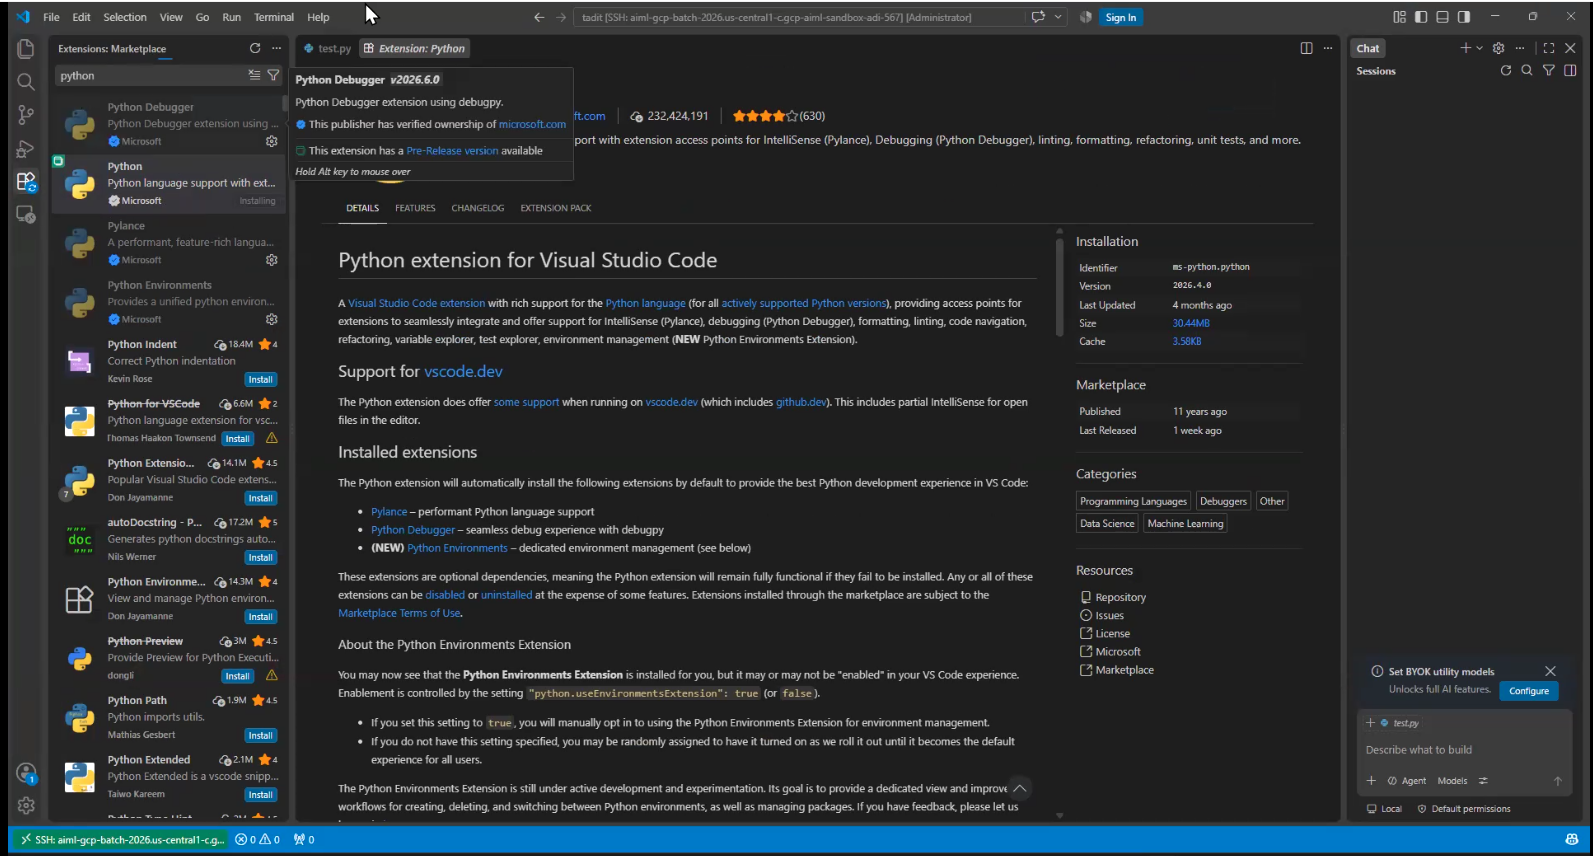

## If you want to remove old compute then 

```bash
gcloud compute config-ssh --remove
```

### Create a new folder -> test 

```bash
create a new test.py file -> print("Hello BWT AIML Batch 2026...!")
```

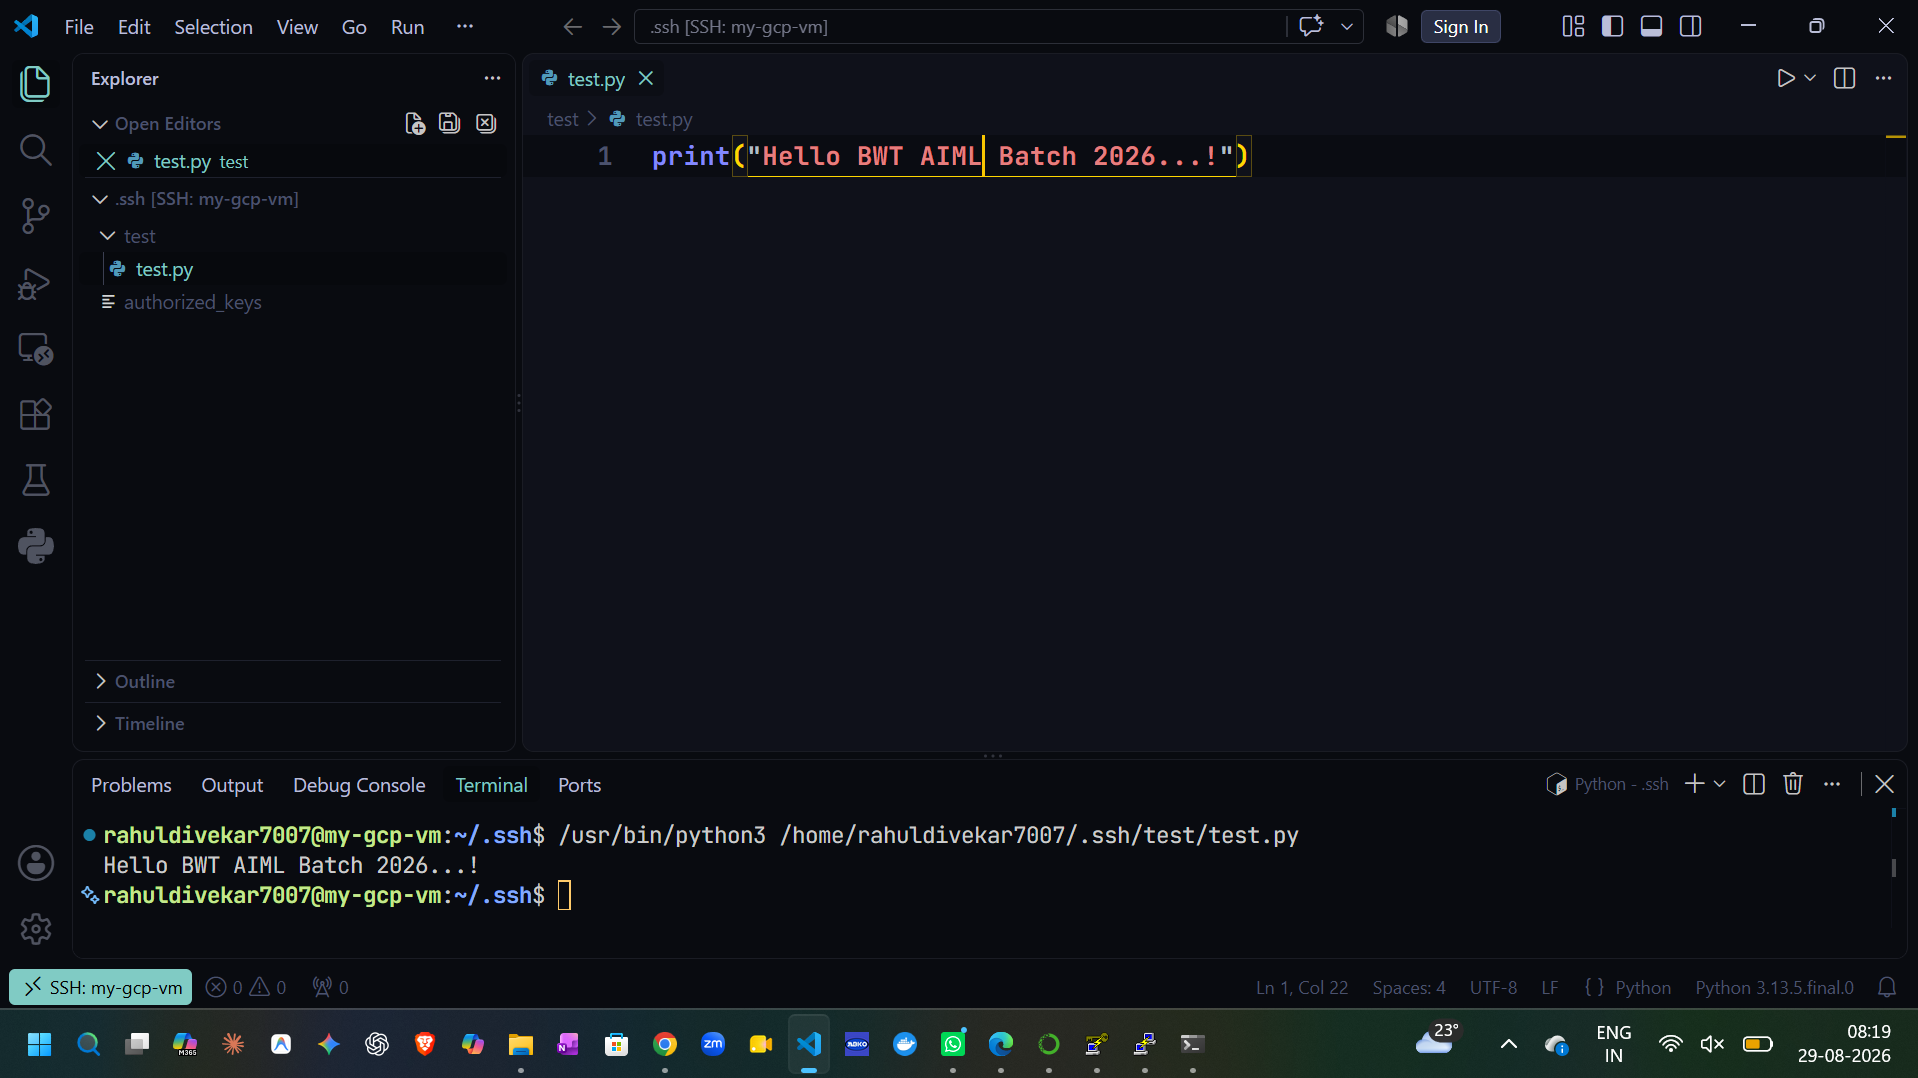

# Now Turn on Bigquery api

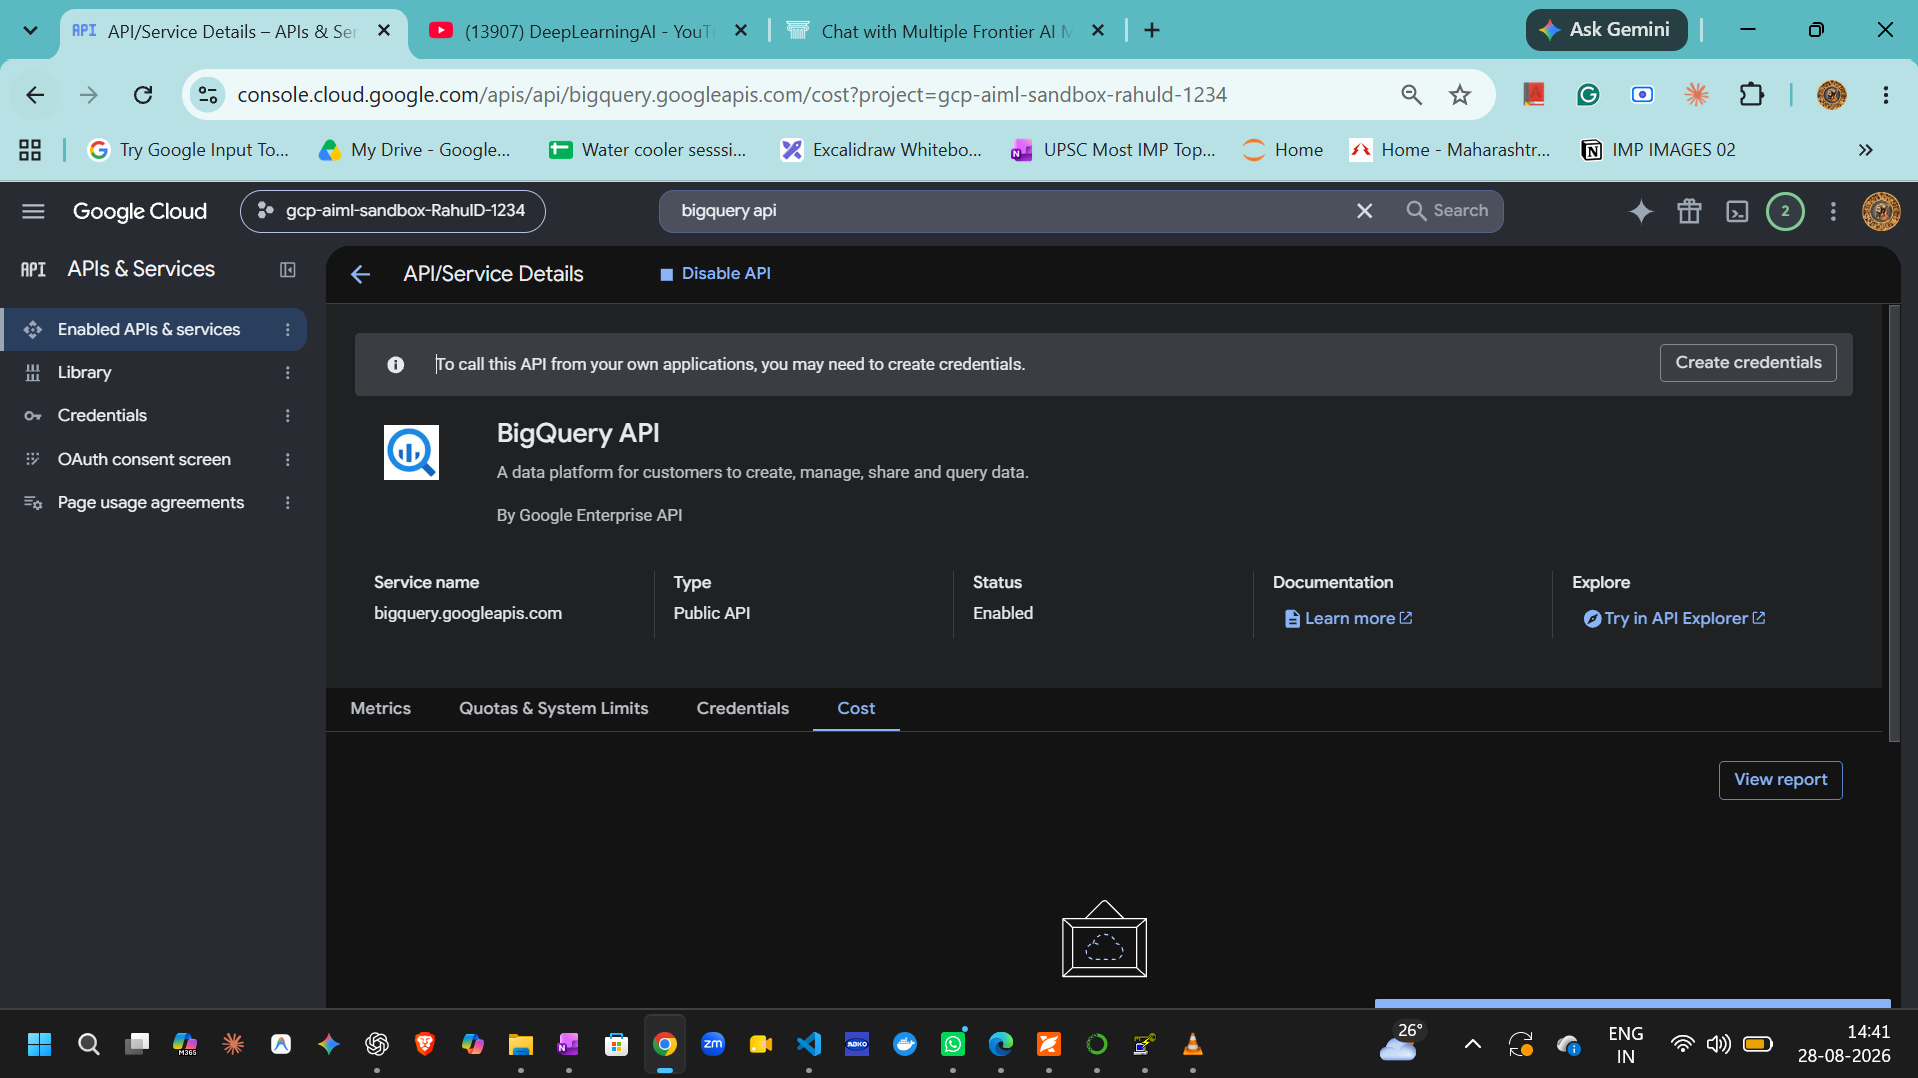

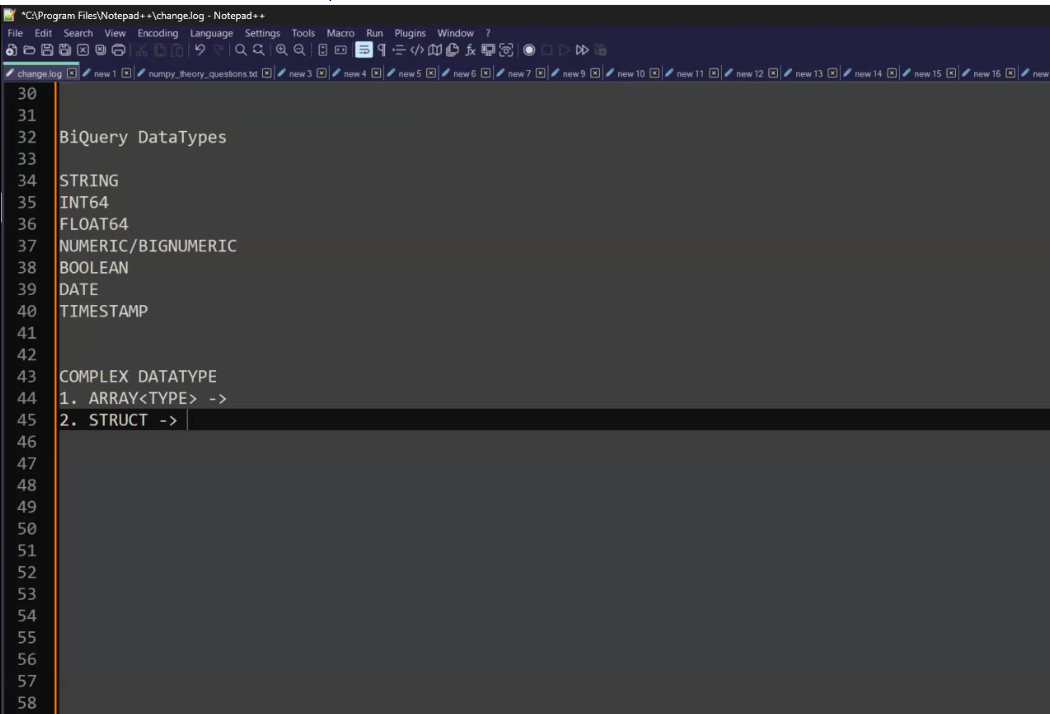

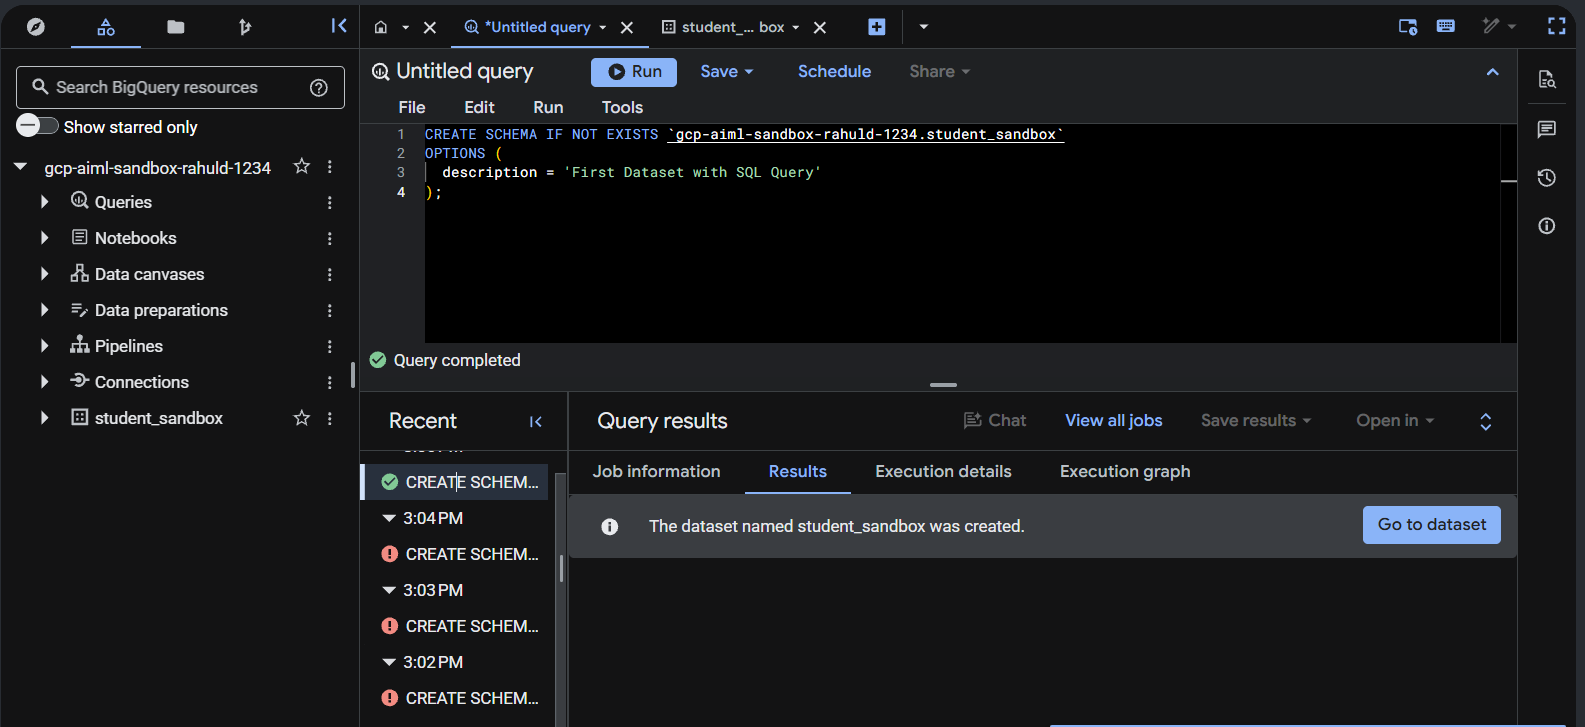

```bash
--Create Dataset
CREATE SCHEMA IF NOT EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox`
OPTIONS (
  description = 'First Dataset with SQL Query'
);

--Create Table
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.customer_tbl` (
  customer_id INT64 NOT NULL,
  signup_date DATE,
  spending_score FLOAT64,
  is_active BOOLEAN,
  location STRUCT<
    city STRING,
    country STRING
  >,
  interest ARRAY<STRING>,
  created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP()
);

--Insert Data into Table
INSERT INTO `gcp-aiml-sandbox-rahuld-1234.student_sandbox.customer_tbl`
  (customer_id, signup_date, spending_score, is_active, location, interest)

VALUES
(
  1001,
  '2026-01-15',
  88.5,
  TRUE,
  STRUCT('Taipei', 'Taiwan'),
  ['machine learning', 'cloud architecture', 'sql']
),
(
  1002,
  '2026-03-22',
  42.1,
  FALSE,
  STRUCT('San Jose', 'United States'),
  ['deep learning', 'computer vision']
),
(
  1003,
  '2026-06-10',
  95.0,
  TRUE,
  STRUCT('Munich', 'Germany'),
  ['big data', 'mlops', 'kubernetes']
);

select * from `gcp-aiml-sandbox-rahuld-1234.student_sandbox.customer_tbl`;

-- Accessing Struct type data values
select customer_id, spending_score, location.city as city, location.country as country from `gcp-aiml-sandbox-rahuld-1234.student_sandbox.customer_tbl`;

-- Accessing Array Type Data Values
select customer_id, interest, from `gcp-aiml-sandbox-rahuld-1234.student_sandbox.customer_tbl`, unnest(interest) as interest_val;

--Run Student Score

select * from `gcp-aiml-sandbox-rahuld-1234.student_sandbox.student_score`;

-- Create bigquery table pointing to GCS

CREATE OR REPLACE EXTERNAL TABLE
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.student_scores_gcs`
(
  student_id INT64,
  student_name STRING,
  midterm_score INT64,
  final_score INT64,
  passed BOOLEAN
)
OPTIONS (
  format = 'CSV',
  uris = ['gs://gcp-aiml-sandbox-rahuld-1234-data/student_score.csv'],
  skip_leading_rows = 1
);

select * from `gcp-aiml-sandbox-rahuld-1234.student_sandbox.student_scores_gcs`;

-- Alternative: Using auto-detection via console with GCS URIs

-- Querying table metadata / columns
SELECT column_name, data_type, is_nullable
FROM `gcp-aiml-sandbox-rahuld-1234.student_sandbox.INFORMATION_SCHEMA.COLUMNS`
WHERE table_name = 'customer_tbl';

-- 1. Add a new column
ALTER TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.customer_tbl`
ADD COLUMN credit_score INT64;

-- 2. Rename a column
ALTER TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.customer_tbl`
RENAME COLUMN spending_score TO user_score;

-- 3. Drop an obsolete column
ALTER TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.customer_tbl`
DROP COLUMN IF EXISTS is_active;

-- 4. Drop an individual tables
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.student_scores`;

DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.student_scores_gcs`;

-- 5. Drop the entire dataset

DROP SCHEMA IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox`
CASCADE;

```

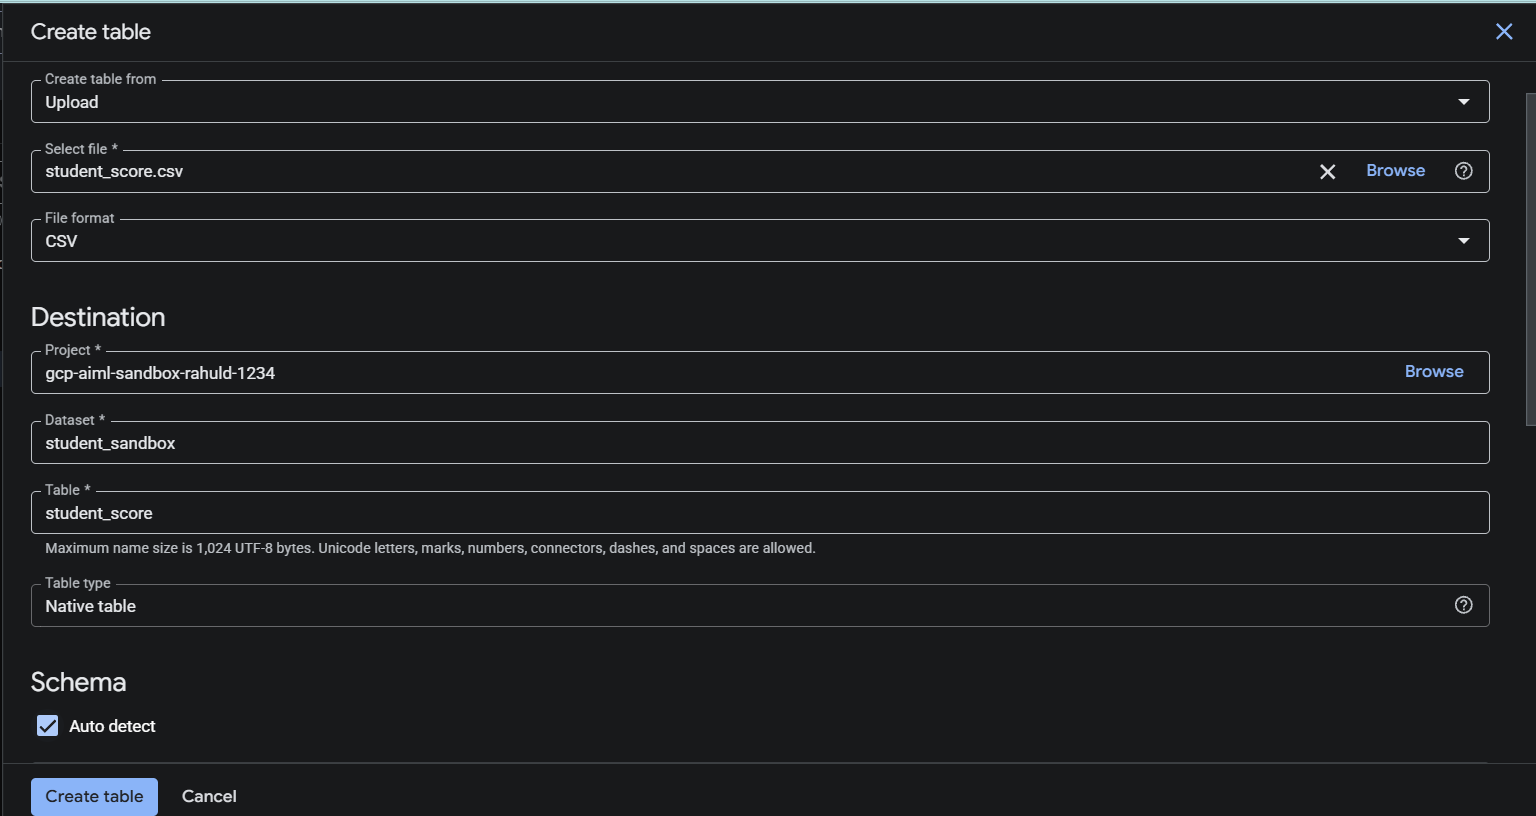

# Bigquery Public Dataset:- tlc_yellow_trips_2018

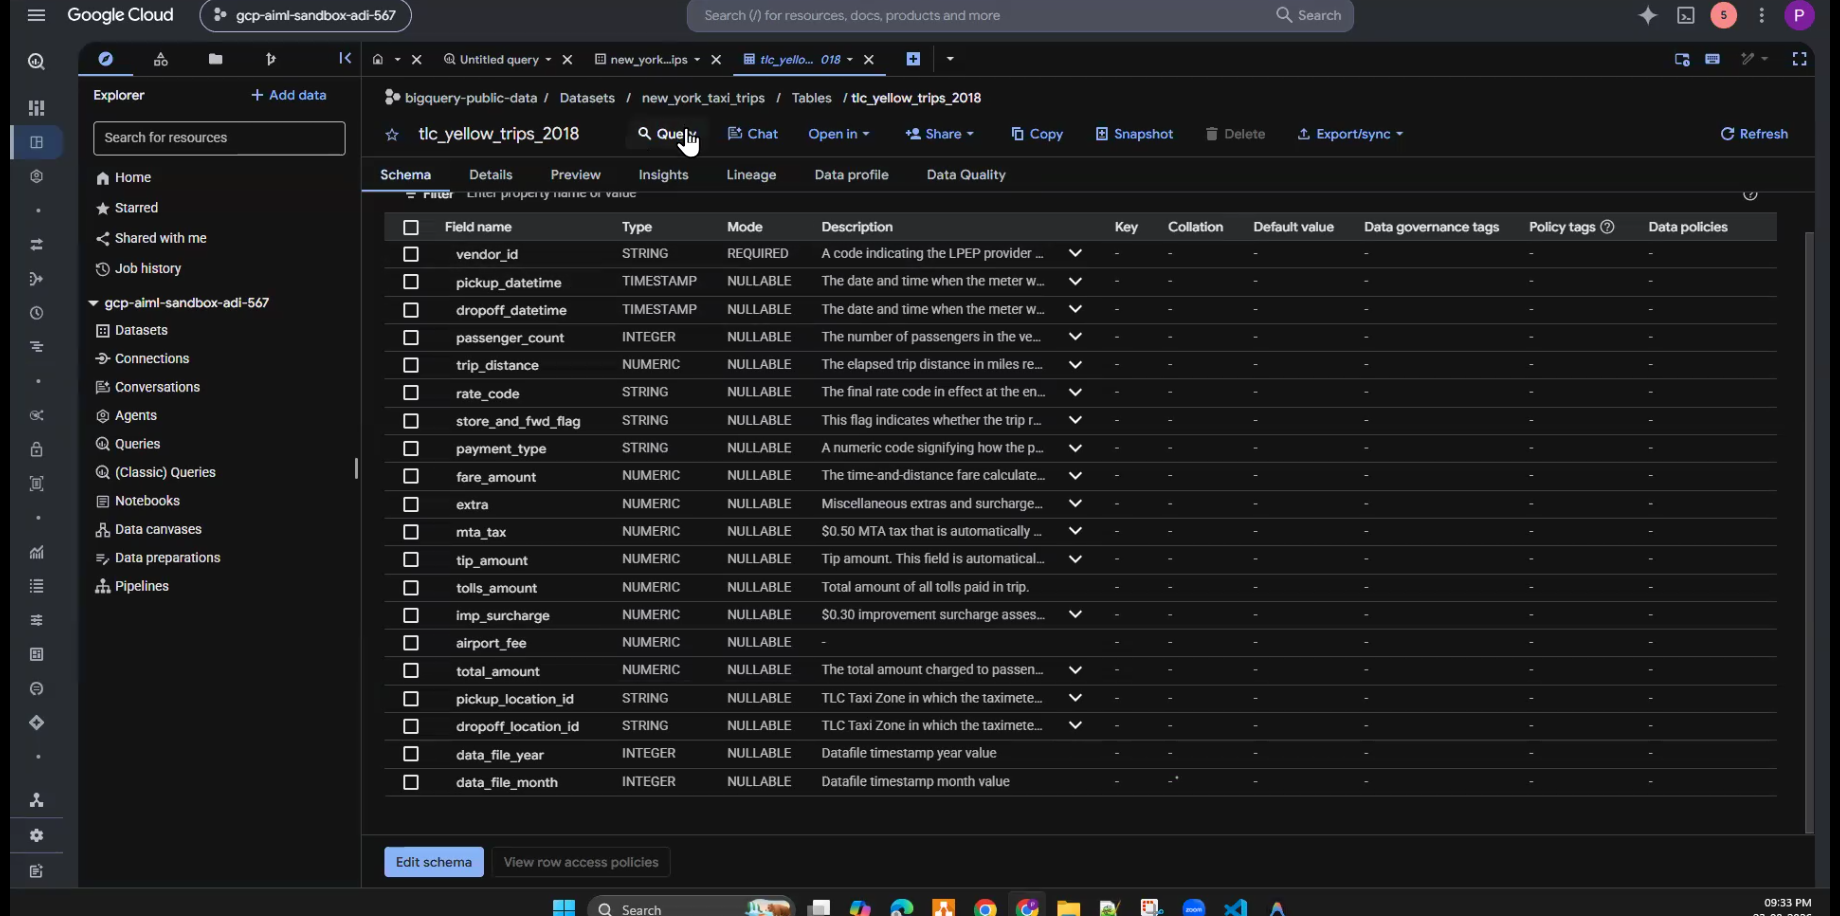

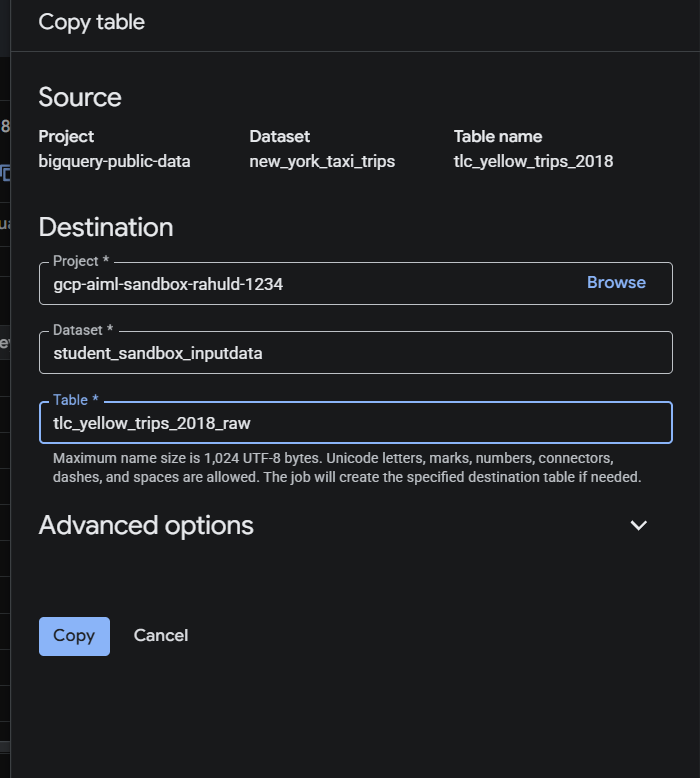


```bash
https://docs.cloud.google.com/bigquery/docs/reference/standard-sql/bigqueryml-syntax-create-glm?hl=en
```

# Linear Regression Model

```bash
-- Create a schema/dataset in the Taiwan region
CREATE SCHEMA IF NOT EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox`
OPTIONS(
  location = 'US'
);


-- explore public dataset

select * from `bigquery-public-data.new_york_taxi_trips.tlc_yellow_trips_2018`;


-- Query to explore and cleanse the taxi data
SELECT
  fare_amount,
  trip_distance,
  passenger_count,
  EXTRACT(HOUR FROM pickup_datetime) AS pickup_hour,
  EXTRACT(DAYOFWEEK FROM pickup_datetime) AS pickup_day
FROM
  `bigquery-public-data.new_york_taxi_trips.tlc_yellow_trips_2018`
WHERE
  -- Data Quality Filters: Eliminate obvious anomalies
  fare_amount BETWEEN 2.50 AND 200.00
  AND trip_distance > 0.0
  AND passenger_count > 0
  -- Use a stable random hash to pull a manageable sample of 100,000 rows
  AND MOD(ABS(FARM_FINGERPRINT(CAST(pickup_datetime AS STRING))), 1000) = 1;


-- Create a physical training table from the cleansed public data sample
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.tlc_yellow_trips_2018` AS
SELECT
  fare_amount,
  trip_distance,
  passenger_count,
  CAST(EXTRACT(HOUR FROM pickup_datetime) AS STRING) AS pickup_hour,
  CAST(EXTRACT(DAYOFWEEK FROM pickup_datetime) AS STRING) AS pickup_day
FROM `gcp-aiml-sandbox-rahuld-1234.student_sandbox.tlc_yellow_trips_2018`
WHERE
  fare_amount BETWEEN 2.50 AND 200.00
  AND trip_distance > 0.0
  AND passenger_count > 0
  AND MOD(ABS(FARM_FINGERPRINT(CAST(pickup_datetime AS STRING))), 1000) = 1;

--------------------------------------------------

-- Train a BQML Linear Regression model
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.taxi_fare_model`
OPTIONS (
  model_type = 'linear_reg',
  input_label_cols = ['fare_amount']
) AS
SELECT
  fare_amount,
  trip_distance,
  passenger_count,
  pickup_datetime  
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.tlc_yellow_trips_2018`;

-- Understanding BQML Training:
-- model_type = 'linear_reg': Instructs BigQuery to run a multivariate linear regression algorithm.
-- input_label_cols = ['fare_amount']: Identifies fare_amount as the target column. Everything else in the SELECT query is automatically treated as an input feature.
-- Auto-tuning: BigQuery automatically splits your data into an 80/20 train/test split, handles feature scaling, and optimizes learning rates.

-- Evaluate the trained model performance
SELECT
  *
FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.taxi_fare_model`);


-- Exact Feature Column
SELECT *
FROM ML.FEATURE_INFO(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.taxi_fare_model`);

-- Generate fare predictions for three unseen future rides
SELECT
  predicted_fare_amount,
  trip_distance,
  passenger_count,
  pickup_datetime
FROM
  ML.PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.taxi_fare_model`,
    (
      -- Match EXACT training types: NUMERIC, INT64/NUMERIC, TIMESTAMP
      SELECT
        CAST(1.5 AS NUMERIC) AS trip_distance,
        1 AS passenger_count,
        TIMESTAMP('2024-03-20 10:00:00 UTC') AS pickup_datetime
      UNION ALL
      SELECT
        CAST(12.4 AS NUMERIC) AS trip_distance,
        2 AS passenger_count,
        TIMESTAMP('2024-03-20 18:00:00 UTC') AS pickup_datetime
      UNION ALL
      SELECT
        CAST(5.0 AS NUMERIC) AS trip_distance,
        1 AS passenger_count,
        TIMESTAMP('2024-03-20 08:00:00 UTC') AS pickup_datetime
    )
  );

-- Clean up all created resources
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.taxi_fare_model`;
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.taxi_training_date`;
DROP SCHEMA IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox` CASCADE;
```

---
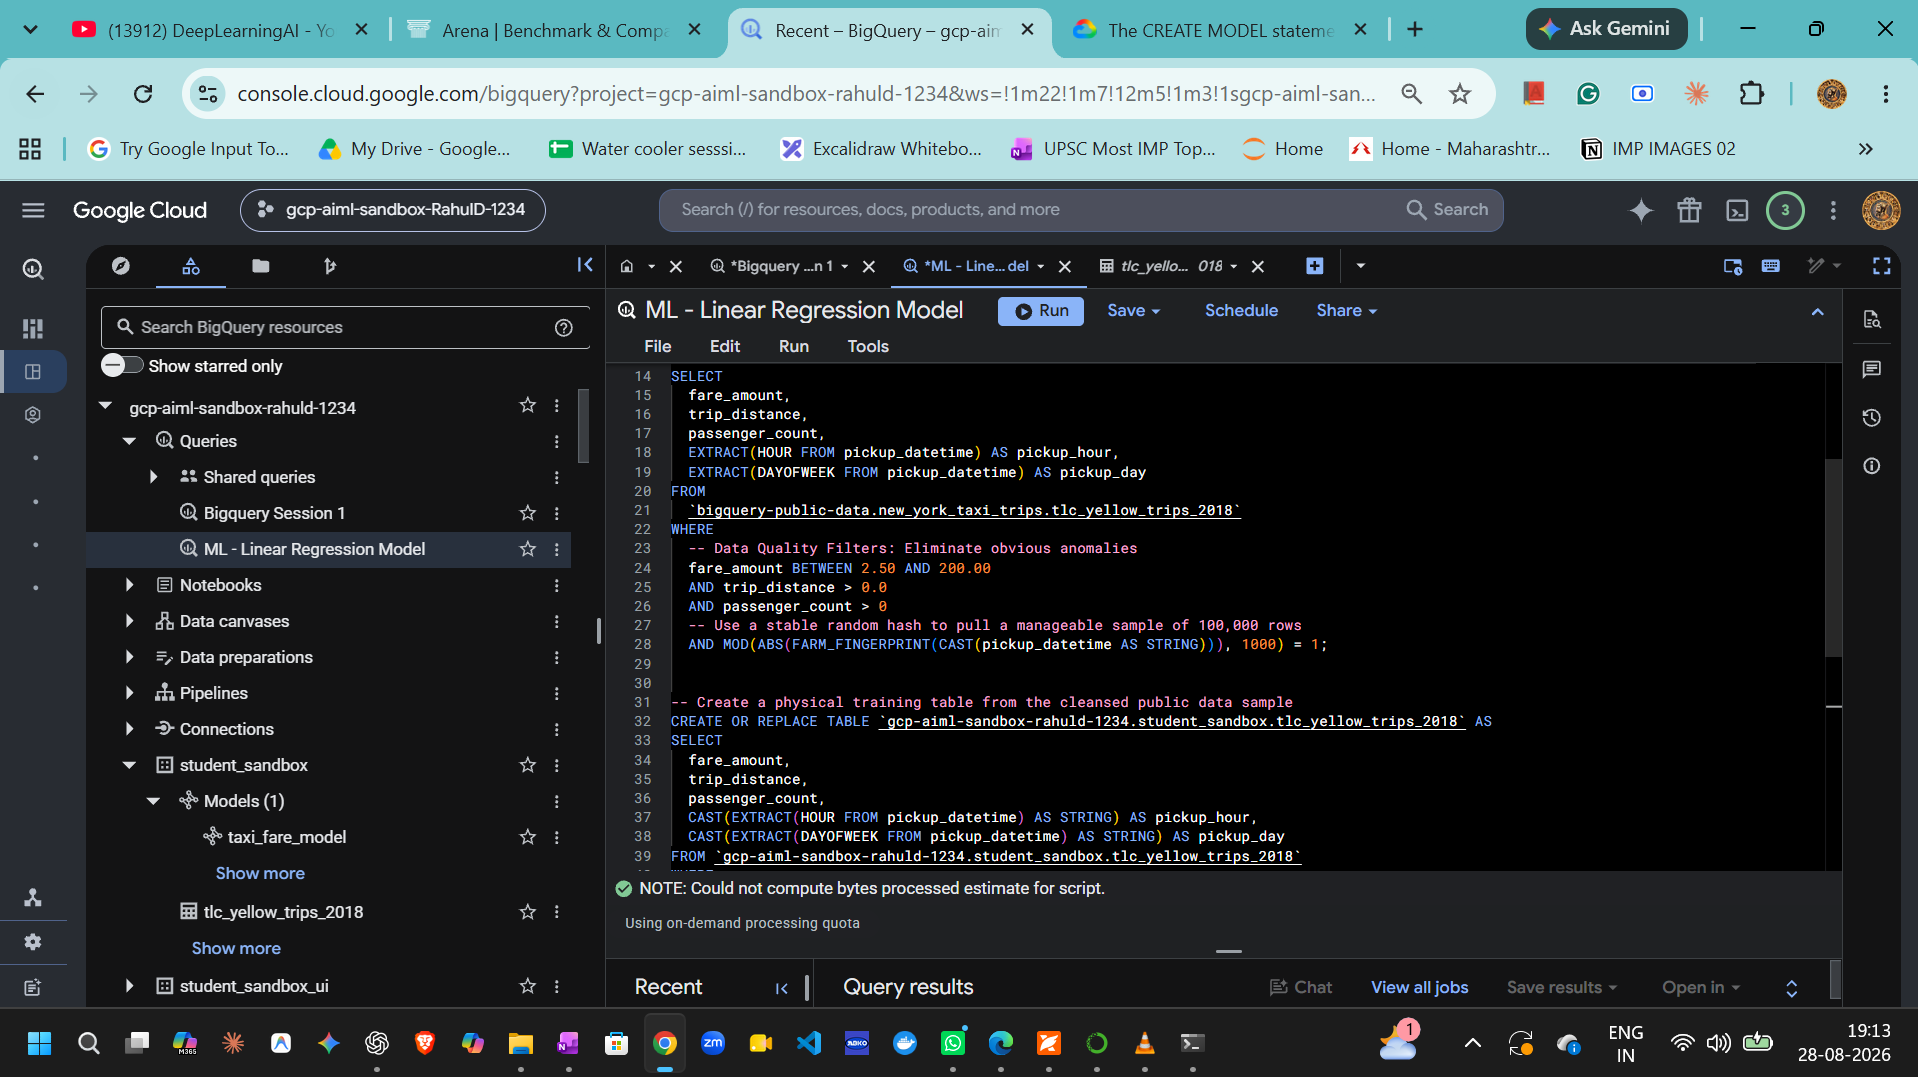

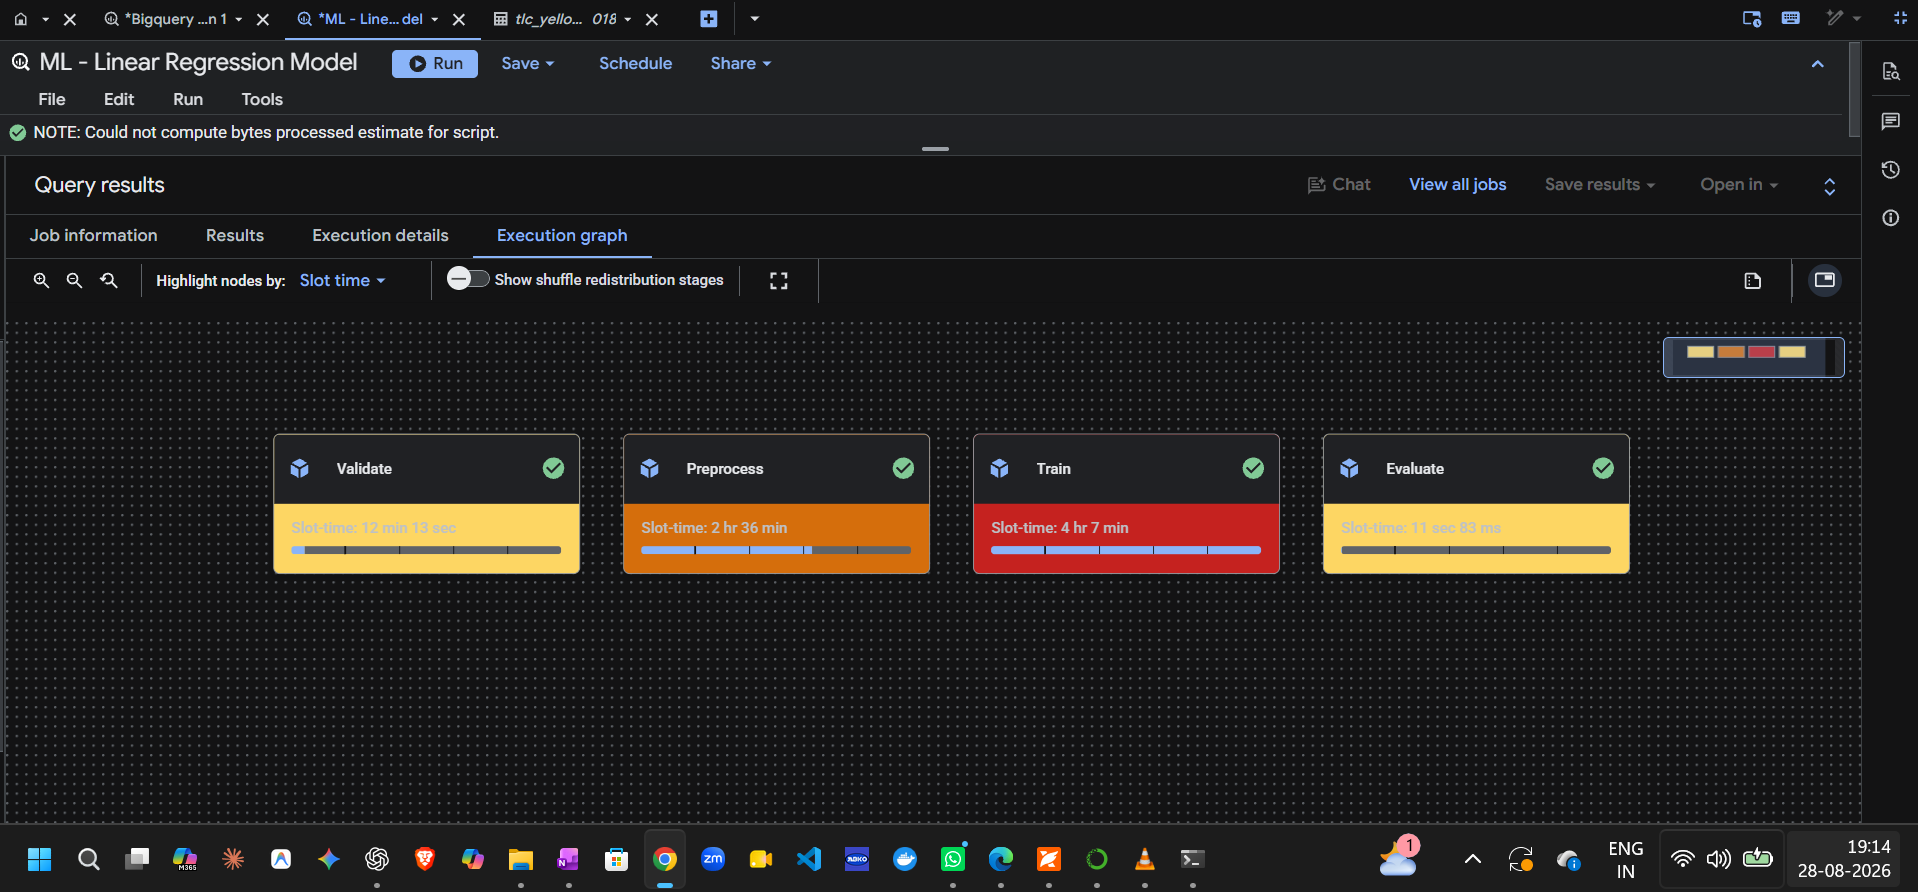

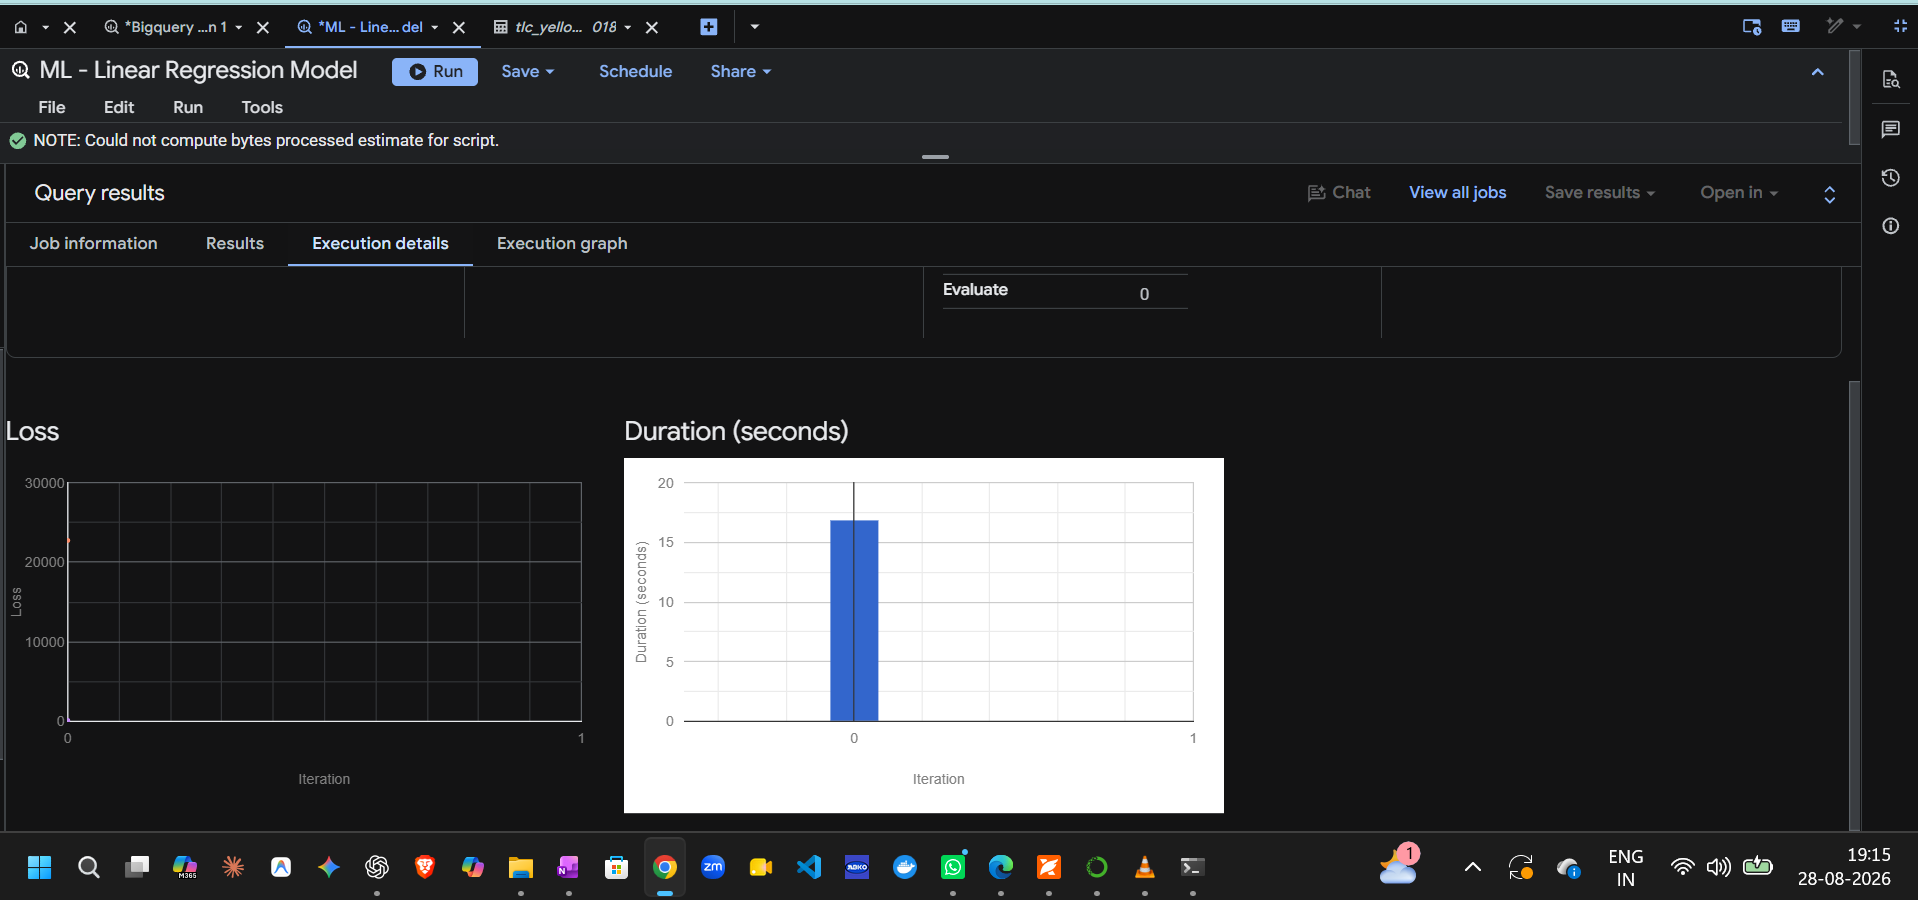

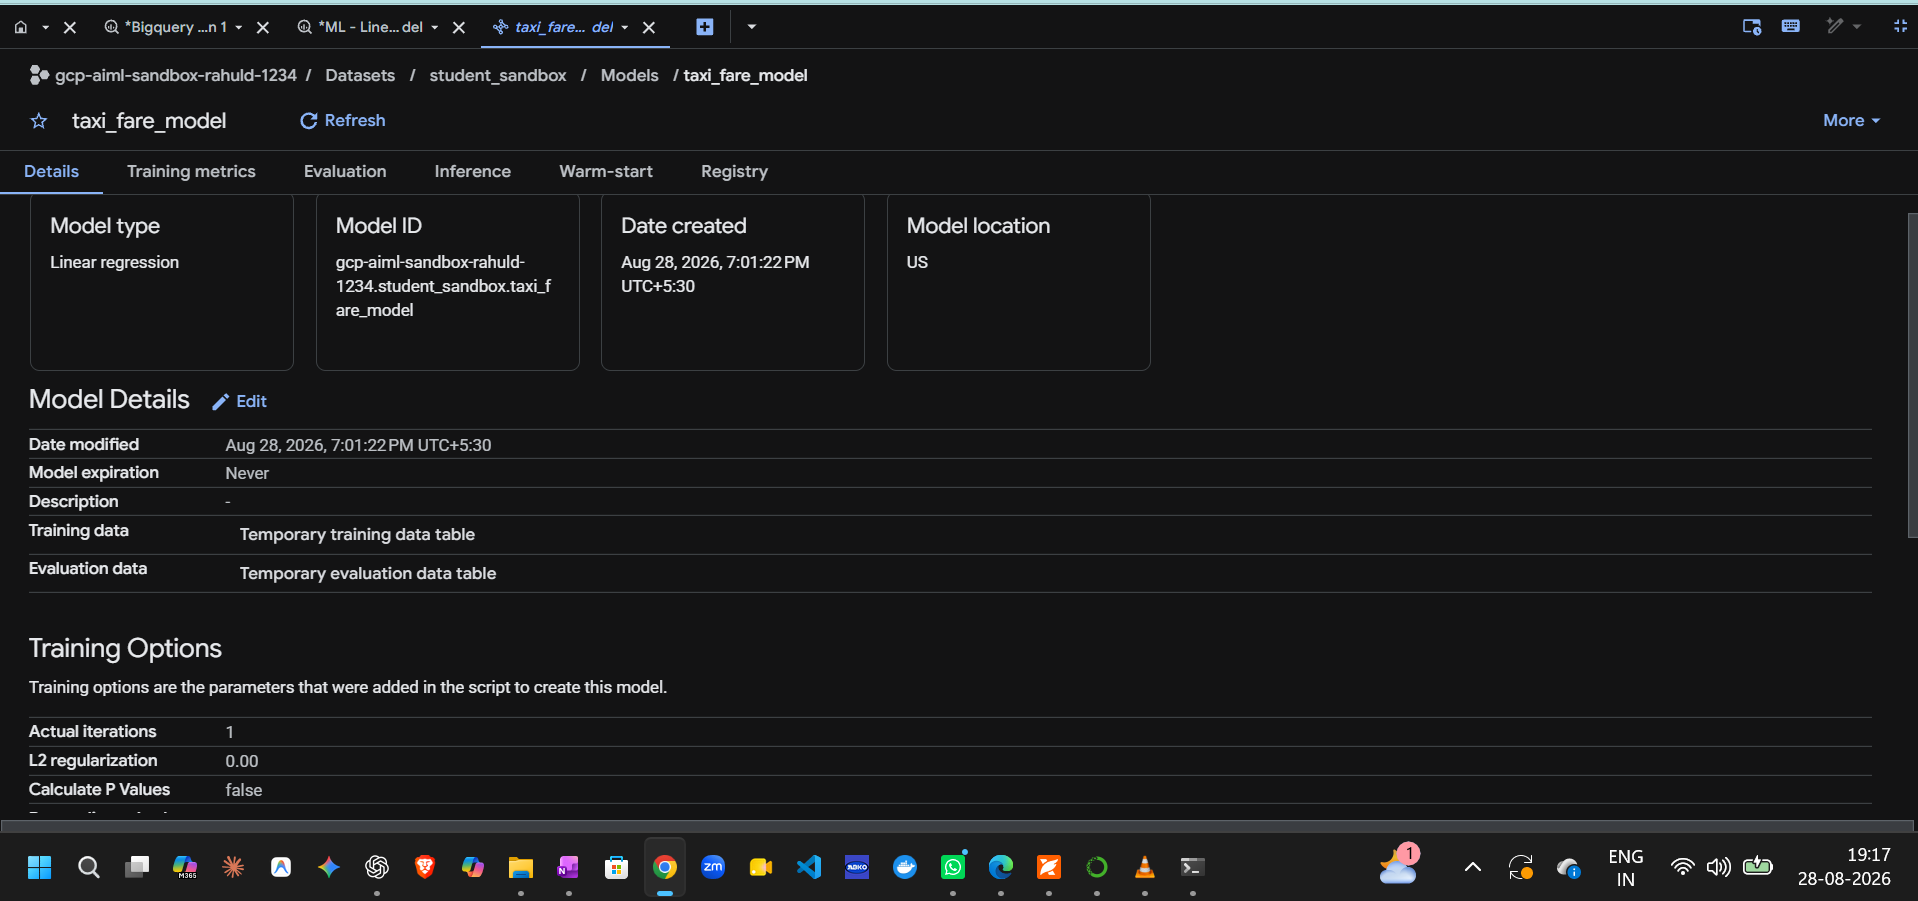

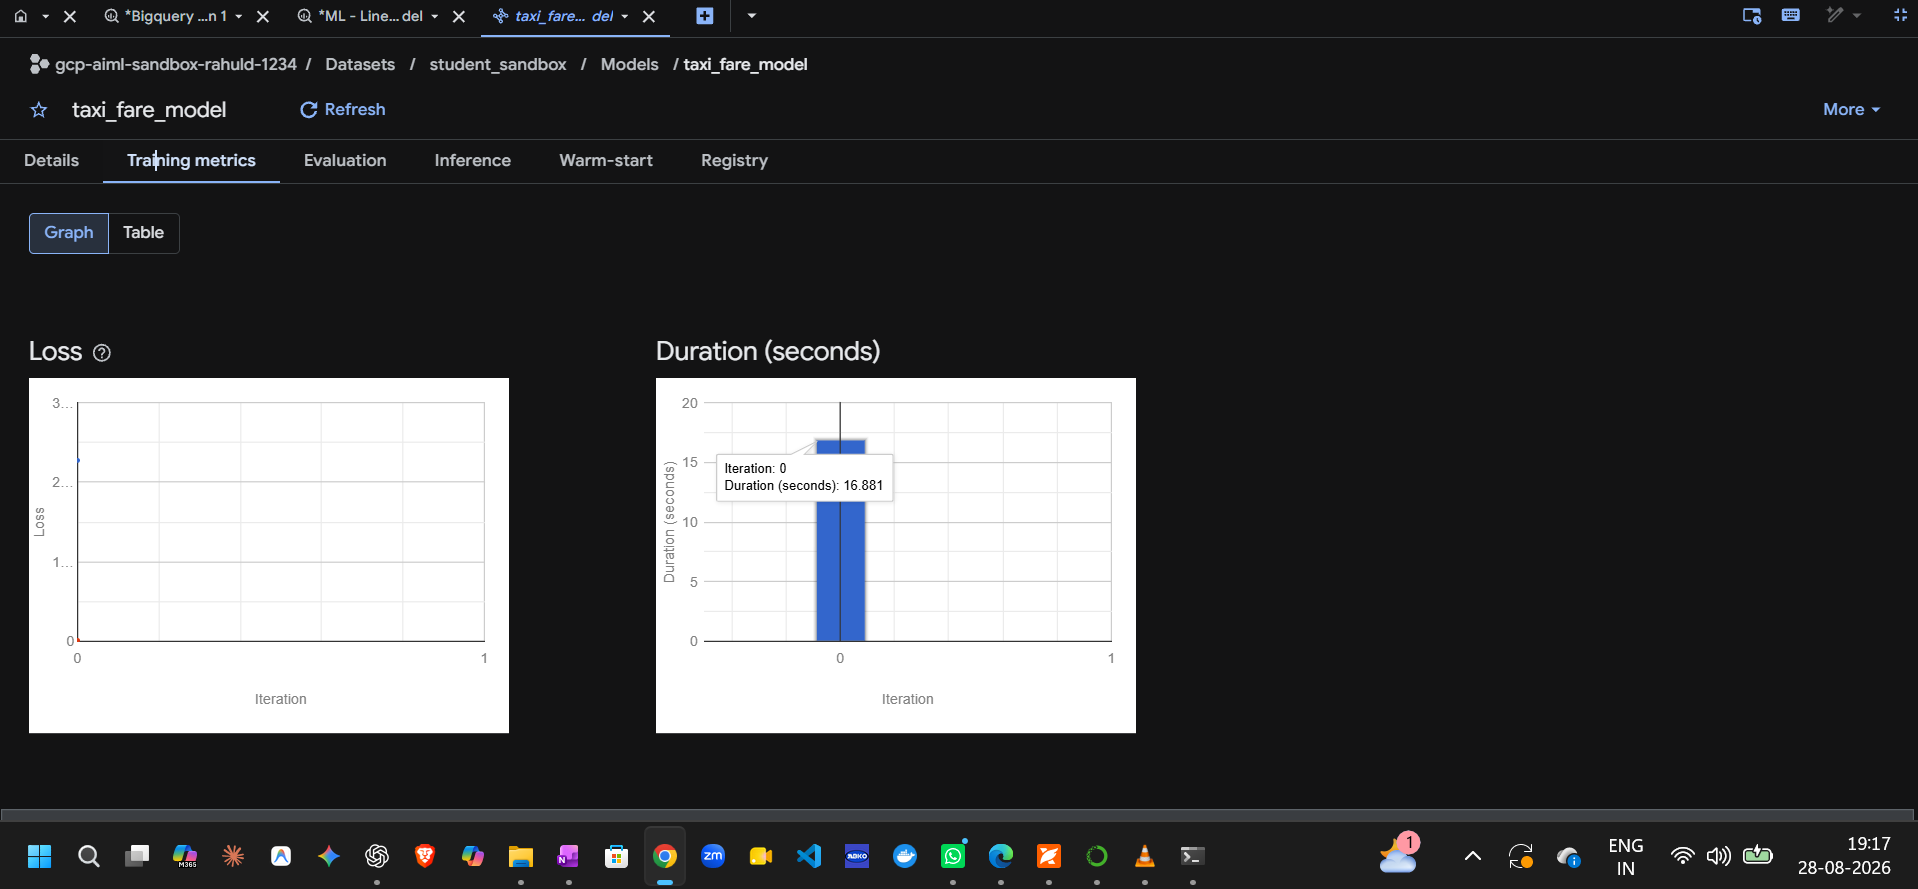

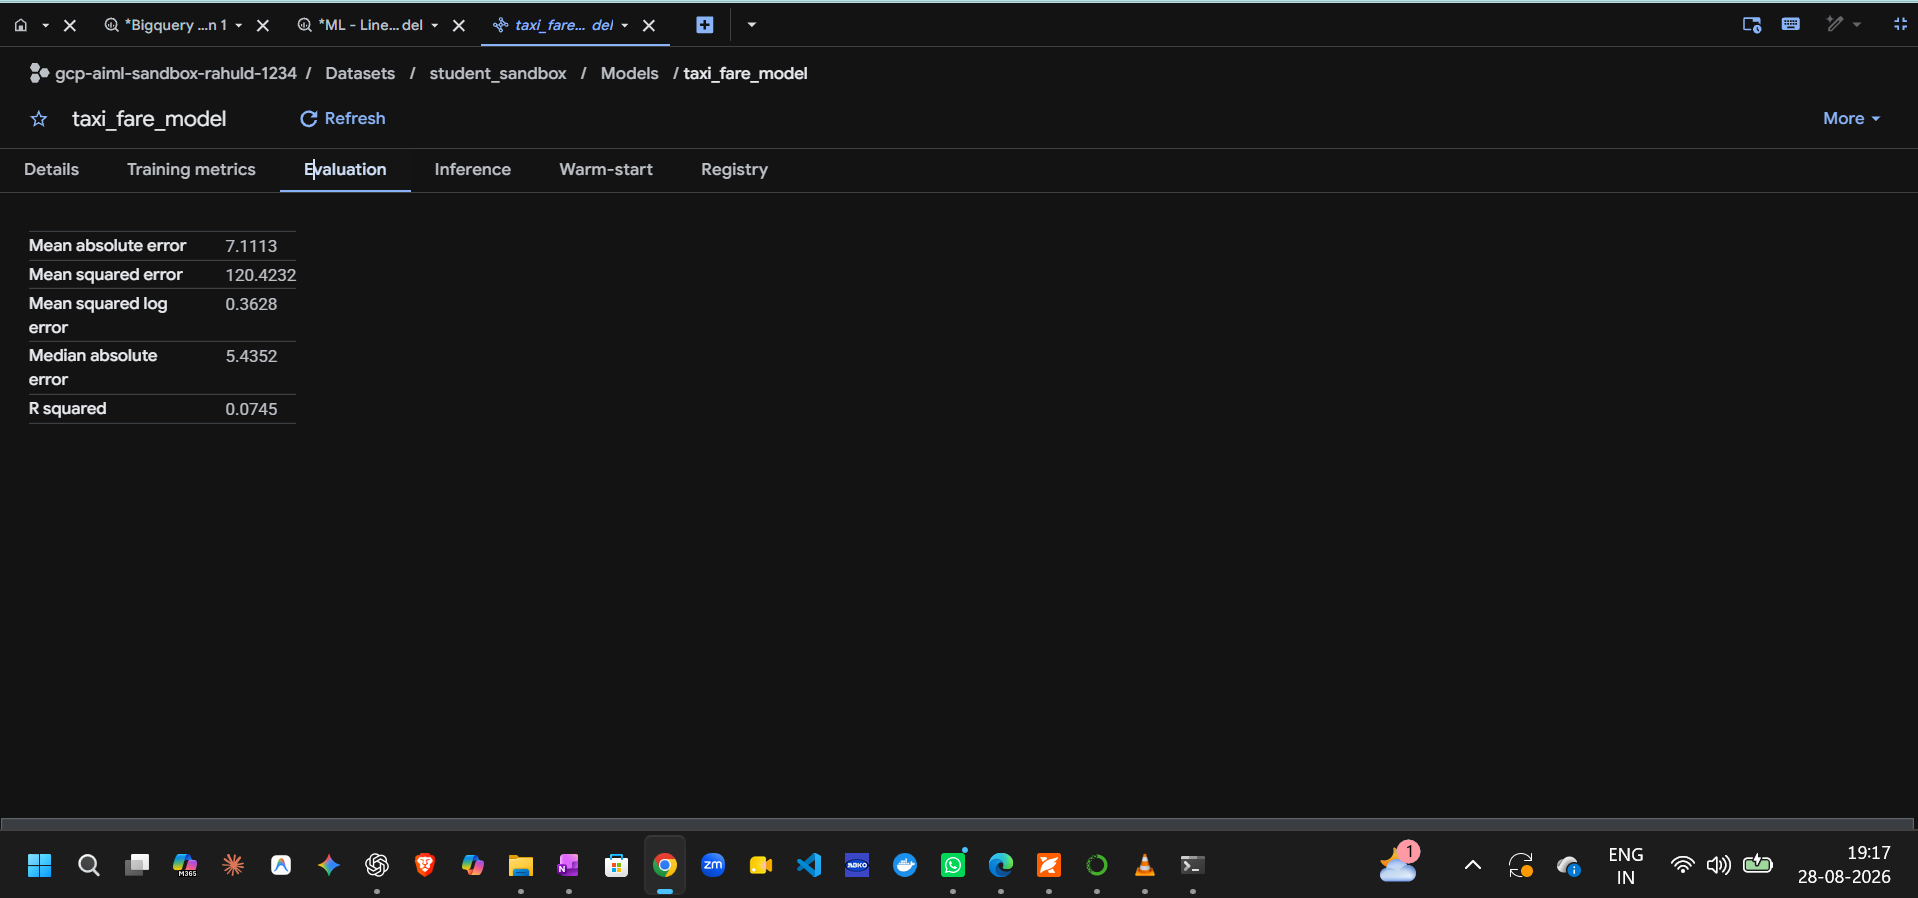

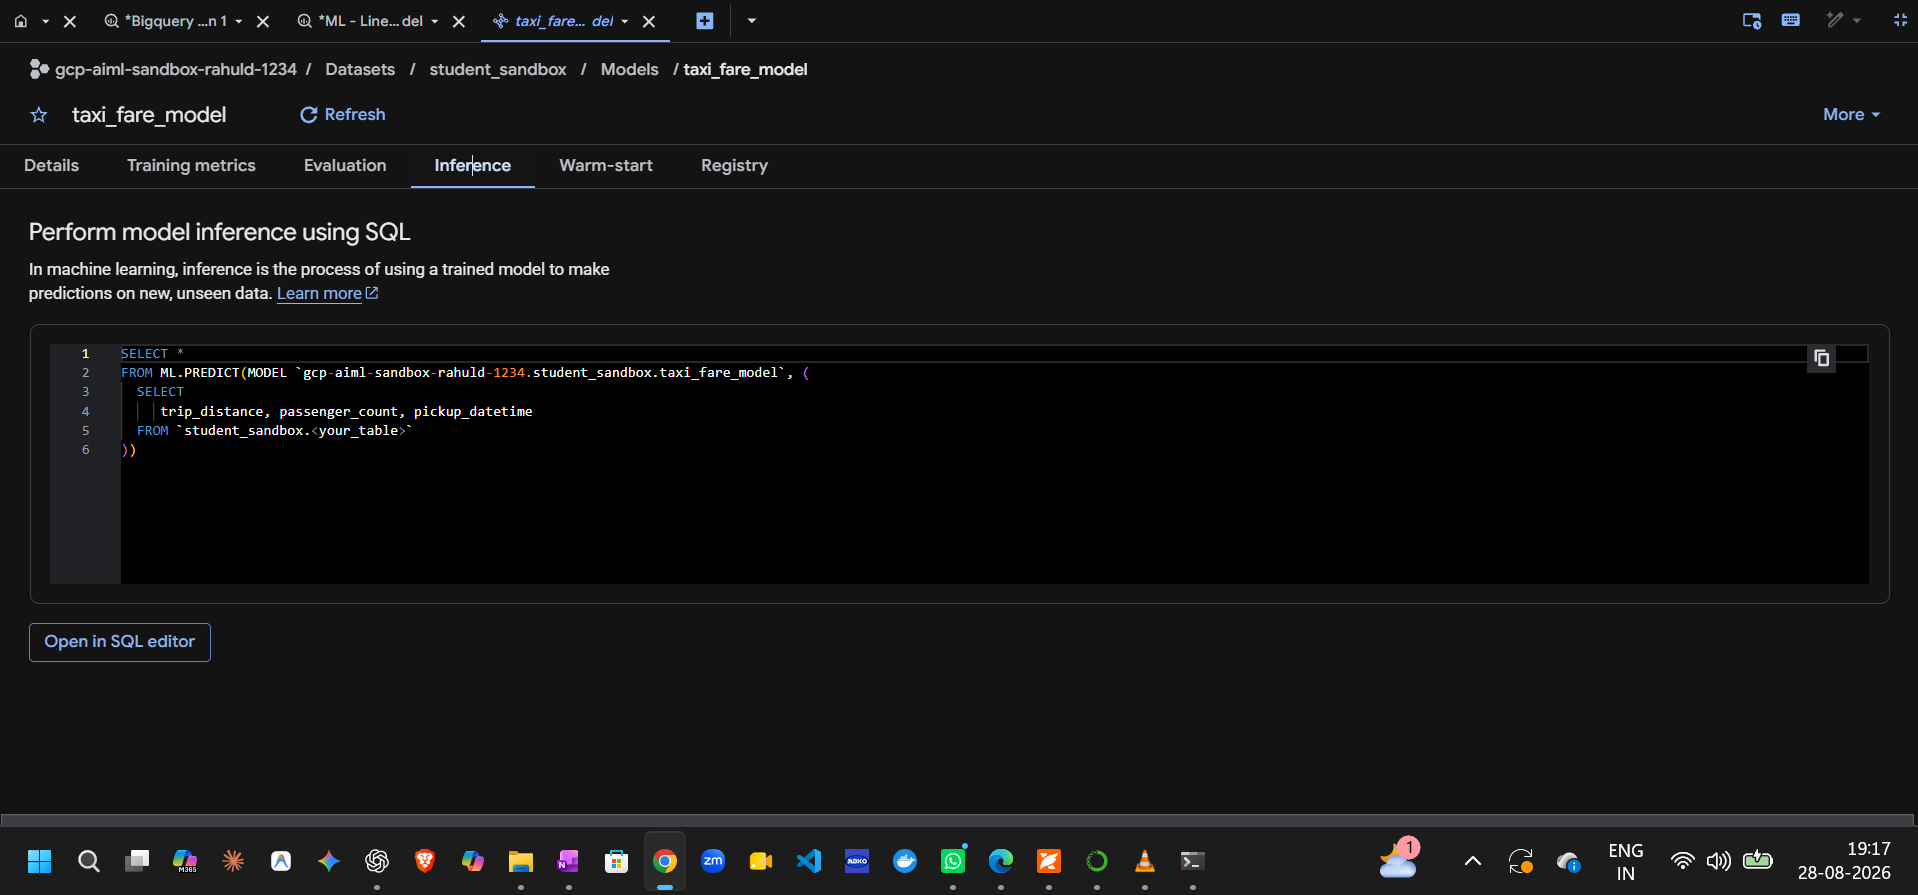

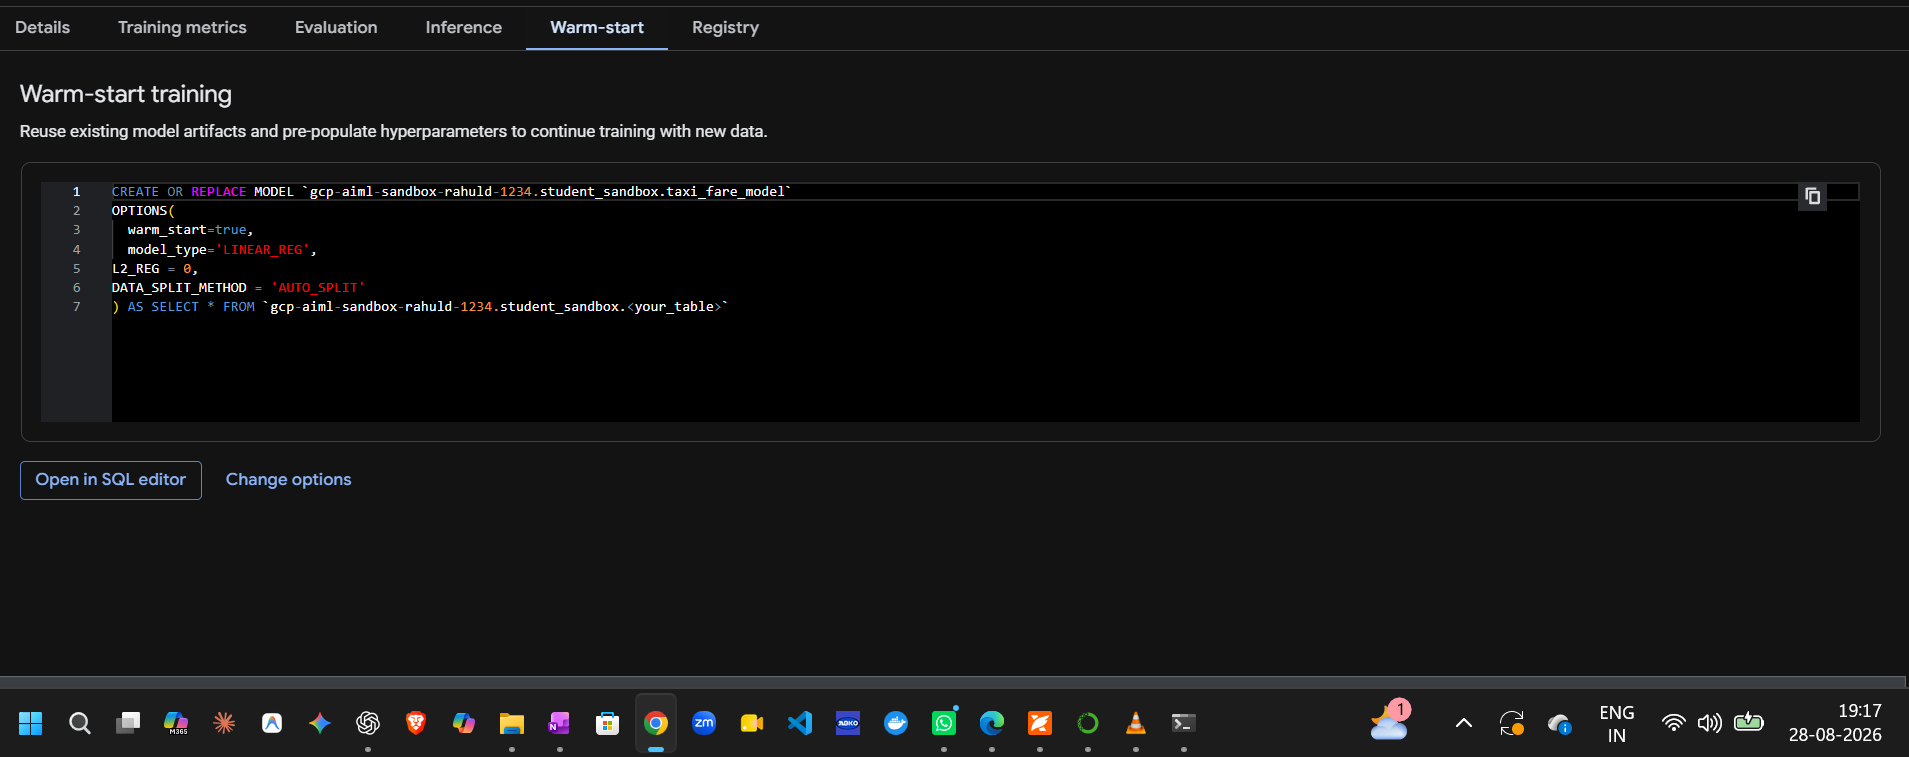

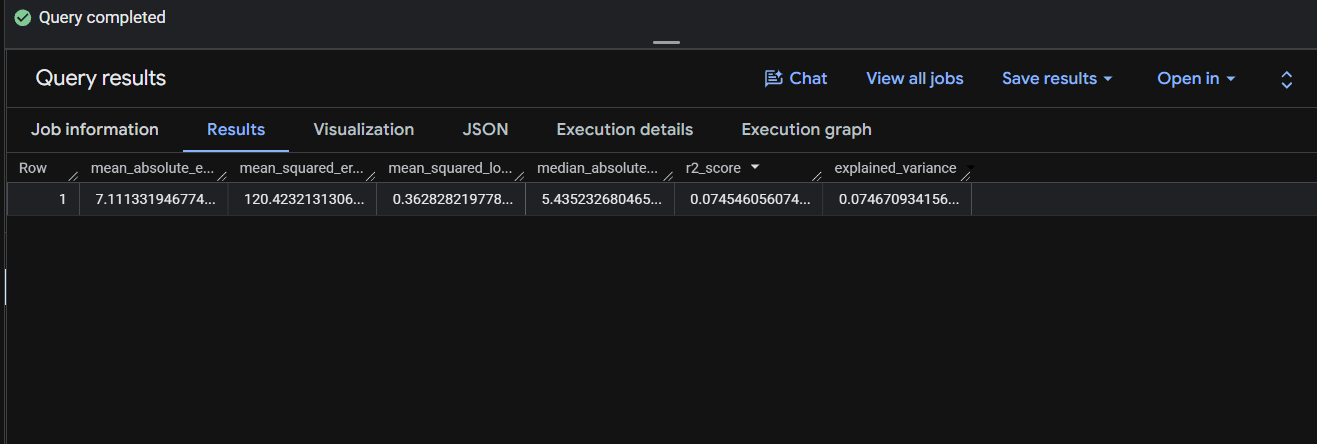

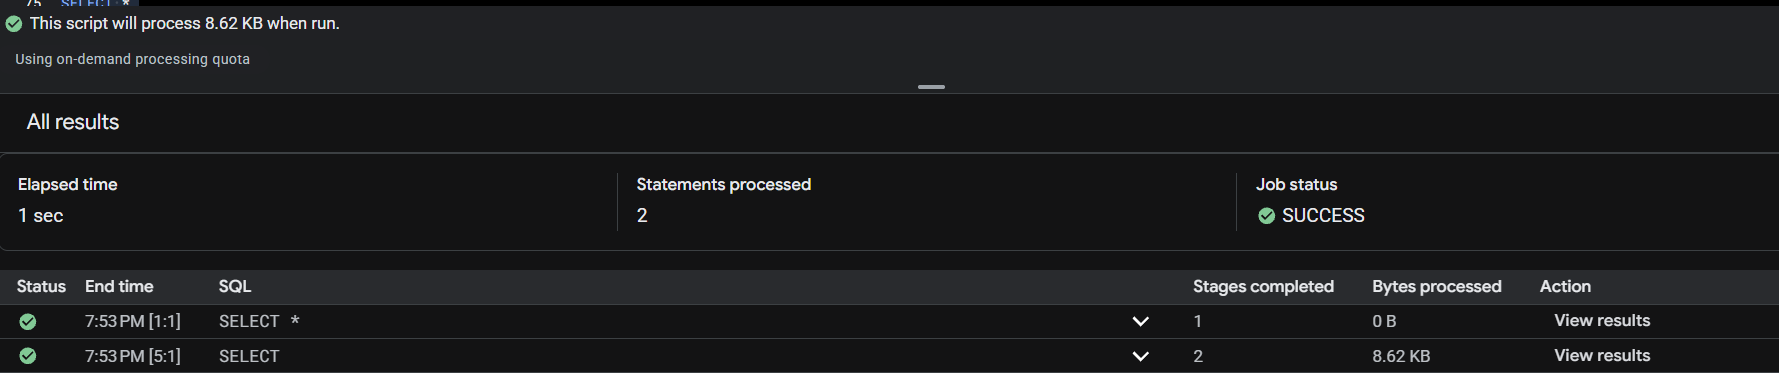
